# Reverse-Engineering the IOI Circuit in GPT-2 Small
### Activation Patching, Path Patching and a Generalization Test
**Bhargav R Rao · 1RUB25CSE0004 · RV University · M.Tech XAI Mini Project**

This notebook does everything on the slides, in order:

| Part | What it does | Slide |
|---|---|---|
| 1 | Load GPT-2 small, build the IOI prompt dataset, check the model solves the task | 3 |
| 2 | **Activation patching** sweep over all 144 heads (two directions) | 7 (box 2) |
| 3 | **Path patching**: direct effect on logits, then trace back to Name Movers → S-Inhibition → earlier heads | 7 (box 3) |
| 4 | Assemble the circuit and compare with Wang et al. (ICLR 2023) | 7 (box 4) |
| 5 | **Generalization test** (your novelty): same analysis on Animals / Objects / Colors tasks | 7 (box 5) |
| 6 | **Circuit validation**: faithfulness, completeness, minimality (Wang's criteria), also applied to the new tasks | 7 (box 4-5) |
| 7 | **Mechanism check**: do Name Movers still attend to the correct entity on the new tasks? | 7 (box 5) |
| 8 | **Re-discover** the circuit on each new task + bootstrap CIs and permutation test | 7 (box 5) |
| 9 | Evidence summary + **what predicts transfer** across 8 task families | 7 (box 5) |
| 10 | **New:** circuit-guided head-pruning curves (does an IOI ranking transfer to other tasks?) | 7-8 |
| – | Save every figure and table | – |

**Hardware.** No GPU is *required* (GPT-2 small is only 124M parameters). A GPU just makes the sweeps ~10-20x faster:
- **Colab:** Runtime → Change runtime type → **T4 GPU** → Run all (about 10-15 min).
- **Laptop CPU:** works, but expect an hour or more. Lower `N_PROMPTS` in the setup cell (e.g. 30) to speed it up.

**How to read the results.** Every sweep produces a 12 × 12 heatmap (layer × head). Bright cells = heads that causally matter. Nothing here uses attention maps or SHAP, every number comes from an intervention.

**If Colab disconnects:** progress is saved to your Google Drive (folder `ioi_project`). Just reconnect and click Runtime → Run all; finished sweeps are loaded from disk (`[resumed]`) instead of recomputed. Allow the Drive pop-up when asked. If you ever *edit the templates*, delete the `ioi_project/checkpoints` folder so stale results aren't reused.

In [ ]:
# Pinned version so the API matches this notebook. (~1 min on Colab)
!pip install -q "transformer_lens==2.16.1" matplotlib pandas tqdm

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
plum-dispatch 2.9.0 requires beartype>=0.16.2; python_version < "3.14", but you have beartype 0.14.1 which is incompatible.


In [ ]:
import os, random
from dataclasses import dataclass, field, replace
from functools import partial
from typing import List, Optional

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from transformer_lens import HookedTransformer, utils

torch.set_grad_enabled(False)        # we never train anything, so no gradients are needed
SEED = 0
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

# ---- experiment size (lower this if you are on CPU) ----
N_PROMPTS = 100 if device == "cuda" else 40
OUT_DIR = "results"
os.makedirs(OUT_DIR, exist_ok=True)

Running on: cuda


In [ ]:
# ------------------------------------------------------------------
# SAVE PROGRESS: free Colab sessions can disconnect at any time.
# Every finished sweep is saved to Google Drive; if the session dies, reconnect,
# click Runtime -> Run all, and finished sweeps are loaded instead of recomputed.
# ------------------------------------------------------------------
try:
    from google.colab import drive
    drive.mount("/content/drive")
    BASE = "/content/drive/MyDrive/ioi_project"
    print("Google Drive mounted: progress will survive a disconnect.")
except Exception as e:                      # not on Colab (or Drive access declined)
    BASE = "."
    print("Not using Google Drive (", type(e).__name__, ") - saving next to the notebook instead.")

CKPT_DIR = f"{BASE}/checkpoints"
OUT_DIR  = f"{BASE}/results"
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(OUT_DIR, exist_ok=True)

# The tag makes a checkpoint valid only for the same settings. Change N_PROMPTS or SEED and
# old checkpoints are ignored automatically. If you EDIT THE TEMPLATES, delete the checkpoints folder.
CKPT_TAG = f"n{N_PROMPTS}_seed{SEED}"

def cached(key, fn):
    """Run fn() (an expensive sweep) once; afterwards load the saved result from disk."""
    path = f"{CKPT_DIR}/{CKPT_TAG}__{key}.npy"
    if os.path.exists(path):
        print(f"[resumed] {key}  (loaded from checkpoint, nothing recomputed)")
        return np.load(path)
    out = fn()
    np.save(path, out)
    print(f"[saved]   {key}")
    return out

def heads_key(heads):
    return "_".join(f"{l}-{h}" for l, h in heads)

Mounted at /content/drive
Google Drive mounted: progress will survive a disconnect.


In [ ]:
# "gpt2" in TransformerLens == GPT-2 small (124M params, 12 layers x 12 heads)
model = HookedTransformer.from_pretrained("gpt2", device=device)
model.eval()
n_layers, n_heads = model.cfg.n_layers, model.cfg.n_heads
print(f"layers={n_layers}, heads/layer={n_heads}, total heads={n_layers * n_heads}")
print("Example hook names:", utils.get_act_name("z", 9), "|", utils.get_act_name("q", 9))

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Loaded pretrained model gpt2 into HookedTransformer
layers=12, heads/layer=12, total heads=144
Example hook names: blocks.9.attn.hook_z | blocks.9.attn.hook_q


## Part 1: Dataset (your "prompts")

There is **no training data**; GPT-2 is frozen. The dataset is a set of *probe prompts* with a known correct answer.

For every prompt we build two versions:
- **Clean**: `When John and Mary went to the store, John gave a drink to` → answer ` Mary`
- **Corrupted ("ABC")**: all three names replaced by three *different, unrelated* names, so there is no duplicated name and no right answer (this is exactly Wang et al.'s `p_ABC` distribution).

Names are forced to be **single tokens**, so clean and corrupted prompts have identical length and activations can be swapped position-by-position.

In [ ]:
# ------------------------------------------------------------------
# Word lists
# ------------------------------------------------------------------
NAMES = ["Mary","John","Tom","James","Dan","Sarah","Anna","Paul","Mark","Kate","Alex","David",
         "Emma","Lisa","Peter","Jack","Sam","Ben","Amy","Rose","Mike","Chris","Jane","Bob",
         "Alice","Eric","Laura","Henry","Ryan","Kevin","Julia","Diana","Frank","Grace","Helen",
         "Ian","Jenny","Karen","Leo","Nick"]
PLACES  = ["store","park","school","office","garden","hospital","station","restaurant",
           "library","beach","market","cafe","bank","church","airport","hotel"]
OBJECTS = ["drink","book","ring","kiss","bone","basketball","computer","necklace",
           "apple","letter","flower","phone","gift","pen","ticket","coin"]

# ------------------------------------------------------------------
# IOI templates: the 15 templates from Wang et al. (2023), Appendix E.
#   {S1},{S2} = the subject (1st / 2nd mention)   {IO} = indirect object = CORRECT ANSWER
# ------------------------------------------------------------------
IOI_TEMPLATES = [
 "Then, {S1} and {IO} went to the {PLACE}. {S2} gave a {OBJECT} to",
 "Then, {S1} and {IO} had a lot of fun at the {PLACE}. {S2} gave a {OBJECT} to",
 "Then, {S1} and {IO} were working at the {PLACE}. {S2} decided to give a {OBJECT} to",
 "Then, {S1} and {IO} were thinking about going to the {PLACE}. {S2} wanted to give a {OBJECT} to",
 "Then, {S1} and {IO} had a long argument, and afterwards {S2} said to",
 "After {S1} and {IO} went to the {PLACE}, {S2} gave a {OBJECT} to",
 "When {S1} and {IO} got a {OBJECT} at the {PLACE}, {S2} decided to give it to",
 "When {S1} and {IO} got a {OBJECT} at the {PLACE}, {S2} decided to give the {OBJECT} to",
 "While {S1} and {IO} were working at the {PLACE}, {S2} gave a {OBJECT} to",
 "While {S1} and {IO} were commuting to the {PLACE}, {S2} gave a {OBJECT} to",
 "After the lunch, {S1} and {IO} went to the {PLACE}. {S2} gave a {OBJECT} to",
 "Afterwards, {S1} and {IO} went to the {PLACE}. {S2} gave a {OBJECT} to",
 "Then, {S1} and {IO} had a long argument. Afterwards {S2} said to",
 "The {PLACE} {S1} and {IO} went to had a {OBJECT}. {S2} gave it to",
 "Friends {S1} and {IO} found a {OBJECT} at the {PLACE}. {S2} gave it to",
]

# ------------------------------------------------------------------
# GENERALIZATION tasks (your novelty): SAME logic, different kind of entity.
#   two entities are introduced -> one is mentioned again -> predict the OTHER one
# ------------------------------------------------------------------
ANIMALS = ["cat","dog","bird","fish","horse","cow","pig","sheep","duck","lion","bear","wolf",
           "fox","mouse","rabbit","goat","monkey","snake"]
THINGS  = ["cup","plate","book","pen","chair","table","lamp","box","bag","key","coin","bell",
           "clock","knife","spoon","hat","bottle","phone"]
COLORS  = ["red","blue","green","yellow","black","white","pink","orange","purple","brown","gray"]

ANIMAL_TEMPLATES = [
 "When the {S1} and the {IO} went to the {PLACE}, the {S2} gave a {OBJECT} to the",
 "At the {PLACE}, the {S1} and the {IO} were playing. Later the {S2} ran toward the",
 "After the {S1} and the {IO} met in the {PLACE}, the {S2} looked at the",
]
THING_TEMPLATES = [
 "When the {S1} and the {IO} were on the table, someone picked up the {S2} and then looked at the",
 "After the {S1} and the {IO} were washed in the {PLACE}, she dried the {S2} and then the",
 "In the {PLACE}, the {S1} and the {IO} were lying side by side. He took the {S2} and left the",
]
COLOR_TEMPLATES = [
 "When the {S1} car and the {IO} car stopped at the {PLACE}, the {S2} car was followed by the",
 "The {S1} bag and the {IO} bag were in the {PLACE}. Then the {S2} bag was moved next to the",
 "At the {PLACE}, the {S1} ball and the {IO} ball rolled away. The {S2} ball stopped before the",
]

# ---- more entity families (same structure) so we can study WHAT PREDICTS transfer ----
PROFESSIONS = ["doctor","nurse","teacher","lawyer","driver","chef","pilot","farmer","artist","writer",
               "judge","actor","singer","guard","baker","miner"]
FRUITS   = ["apple","banana","orange","grape","lemon","peach","pear","cherry","melon","mango","plum","lime"]
VEHICLES = ["car","bus","truck","train","bike","boat","plane","taxi","van","ship","tram","cart"]
COUNTRIES = ["France","Spain","Italy","China","India","Japan","Russia","Brazil","Egypt","Canada",
             "Germany","Mexico","Turkey","Greece","Poland","Sweden"]

TASKS = {
    "IOI (people)": dict(pool=NAMES,   templates=IOI_TEMPLATES),
    "Animals":      dict(pool=ANIMALS, templates=ANIMAL_TEMPLATES),
    "Objects":      dict(pool=THINGS,  templates=THING_TEMPLATES),
    "Colors":       dict(pool=COLORS,  templates=COLOR_TEMPLATES),
    "Professions":  dict(pool=PROFESSIONS, templates=ANIMAL_TEMPLATES),   # "the doctor and the nurse ..."
    "Fruits":       dict(pool=FRUITS,      templates=ANIMAL_TEMPLATES),
    "Vehicles":     dict(pool=VEHICLES,    templates=ANIMAL_TEMPLATES),
    "Countries":    dict(pool=COUNTRIES,   templates=IOI_TEMPLATES),      # "France and Spain ..." (name-like)
}

def swap_roles(t):
    """BABA -> ABBA ordering: swap which entity is mentioned first (Wang et al. use both)."""
    return t.replace("{S1}", "@@").replace("{IO}", "{S1}").replace("@@", "{IO}")

# ------------------------------------------------------------------
# Data containers
# ------------------------------------------------------------------
@dataclass
class Group:                       # prompts that share the same token length (can be batched)
    clean: torch.Tensor            # [b, seq]
    corrupt: torch.Tensor          # [b, seq]
    io: torch.Tensor               # [b]  token id of the correct answer
    s: torch.Tensor                # [b]  token id of the repeated (wrong) entity
    prompts: List[str]
    clean_z: Optional[list] = None     # cached head outputs, one tensor per layer
    corrupt_z: Optional[list] = None
    ld_clean_sum: float = 0.0
    @property
    def n(self): return self.clean.shape[0]

@dataclass
class TaskData:
    name: str
    groups: List[Group]
    n: int = 0
    ld_clean: float = 0.0          # mean logit difference, clean runs
    ld_corrupt: float = 0.0        # mean logit difference, corrupted runs
    acc: float = 0.0               # fraction of prompts where logit(IO) > logit(S)

def is_single_token(text):
    return model.to_tokens(text, prepend_bos=False).shape[1] == 1

def tok(word):
    return model.to_single_token(" " + word)

def ld_per_prompt(logits, g):
    """logit difference = logit(correct answer) - logit(repeated entity), at the last position"""
    last = logits[:, -1, :]
    return last.gather(1, g.io[:, None]).squeeze(1) - last.gather(1, g.s[:, None]).squeeze(1)

def get_z(tokens):
    """cache every head's output ('z') for all layers"""
    _, cache = model.run_with_cache(tokens, names_filter=lambda n: n.endswith("attn.hook_z"))
    return [cache[utils.get_act_name("z", l)] for l in range(n_layers)]

def build_task(name, n, seed=SEED):
    spec = TASKS[name]
    rng = random.Random(seed)
    pool = [w for w in spec["pool"] if is_single_token(" " + w)]
    assert len(pool) >= 6, f"not enough single-token words for {name}"
    templates = spec["templates"] + [swap_roles(t) for t in spec["templates"]]

    by_len = {}
    for _ in range(n):
        t = rng.choice(templates)
        io, s, a, b, c = rng.sample(pool, 5)          # a,b,c = unrelated 'ABC' replacements
        used = {io, s, a, b, c}
        kw = dict(PLACE=rng.choice([p for p in PLACES if p not in used]),
                  OBJECT=rng.choice([o for o in OBJECTS if o not in used]))
        clean_txt   = t.format(IO=io, S1=s, S2=s, **kw)   # S appears twice -> duplicate name
        corrupt_txt = t.format(IO=a,  S1=b, S2=c, **kw)   # three different names -> no duplicate
        ct, xt = model.to_tokens(clean_txt), model.to_tokens(corrupt_txt)
        assert ct.shape == xt.shape, "clean/corrupt prompts must have equal length"
        by_len.setdefault(ct.shape[1], []).append((ct[0], xt[0], tok(io), tok(s), clean_txt))

    groups = []
    for _, items in sorted(by_len.items()):
        g = Group(clean=torch.stack([i[0] for i in items]),
                  corrupt=torch.stack([i[1] for i in items]),
                  io=torch.tensor([i[2] for i in items], device=items[0][0].device),
                  s=torch.tensor([i[3] for i in items], device=items[0][0].device),
                  prompts=[i[4] for i in items])
        g.clean_z, g.corrupt_z = get_z(g.clean), get_z(g.corrupt)
        groups.append(g)

    td = TaskData(name=name, groups=groups, n=sum(g.n for g in groups))
    # baselines
    ld_c = ld_x = hits = 0.0
    for g in groups:
        d_clean = ld_per_prompt(model(g.clean), g)
        g.ld_clean_sum = d_clean.sum().item()
        ld_c += g.ld_clean_sum
        ld_x += ld_per_prompt(model(g.corrupt), g).sum().item()
        hits += (d_clean > 0).sum().item()
    td.ld_clean, td.ld_corrupt, td.acc = ld_c / td.n, ld_x / td.n, hits / td.n
    print(f"[{name}] {td.n} prompts in {len(groups)} length-groups | "
          f"logit diff clean={td.ld_clean:.2f}  corrupted={td.ld_corrupt:.2f} | "
          f"accuracy (IO > S) = {td.acc:.0%}")
    return td

In [ ]:
td_ioi = build_task("IOI (people)", N_PROMPTS)

print("\nExample prompts (answer is the name that is NOT repeated):")
for p in td_ioi.groups[0].prompts[:3]:
    print("  ", p, "___")
print("\nTokenised:", model.to_str_tokens(td_ioi.groups[0].clean[0]))
print(f"\nGPT-2 small solves IOI in {td_ioi.acc:.0%} of prompts; Wang et al. report 99.3% and mean logit diff 3.56.")

[IOI (people)] 100 prompts in 7 length-groups | logit diff clean=3.64  corrupted=0.02 | accuracy (IO > S) = 100%

Example prompts (answer is the name that is NOT repeated):
   Then, Alice and Laura had a long argument. Afterwards Laura said to ___
   After David and Emma went to the hotel, David gave a ring to ___
   Then, Emma and Jack had a long argument. Afterwards Jack said to ___

Tokenised: ['<|endoftext|>Then, Alice and Laura had a long argument. Afterwards Laura said to']

GPT-2 small solves IOI in 100% of prompts; Wang et al. report 99.3% and mean logit diff 3.56.


## Part 2 & 3: The two intervention tools

**Activation patching** (one head at a time, all positions)
- *Denoising* (corrupted ← clean): run the corrupted prompt, paste ONE head's clean output into it. Score = how much of the correct behaviour comes back (0 = none, 1 = fully restored).
- *Noising* (clean ← corrupted): run the clean prompt, paste ONE head's corrupted output into it. Score = how much of the behaviour is destroyed.

**Path patching** (Wang et al., Appendix B): isolates *one edge* `sender head → receiver`.
1. Run the clean prompt with every head frozen to its clean output, *except* the sender, which gets its corrupted output.
2. MLPs and layer-norms are recomputed, so the sender's influence flows only through residual stream and MLPs, **never through other heads**.
3. Record what the receivers see, paste that into a normal clean run, and measure the logit difference.

Receiver = `logits` gives the *direct effect* of a head on the output. Receiver = `q` / `v` of other heads traces the circuit backwards.

In [ ]:
# ==================================================================
# ACTIVATION PATCHING
# ==================================================================
def _set_head_hook(z, hook, heads, src):
    for h in heads:
        z[:, :, h, :] = src[:, :, h, :]
    return z

def _base_and_src(g, direction):
    # denoise: run corrupted, paste in clean | noise: run clean, paste in corrupted
    return (g.corrupt, g.clean_z) if direction == "denoise" else (g.clean, g.corrupt_z)

def act_patch_raw(td, direction="denoise"):
    """mean logit difference after patching each single head -> [n_layers, n_heads]"""
    out = np.zeros((n_layers, n_heads))
    for g in tqdm(td.groups, desc=f"activation patching ({direction})", leave=False):
        base, src = _base_and_src(g, direction)
        for l in range(n_layers):
            for h in range(n_heads):
                hook = partial(_set_head_hook, heads=[h], src=src[l])
                logits = model.run_with_hooks(base, fwd_hooks=[(utils.get_act_name("z", l), hook)])
                out[l, h] += ld_per_prompt(logits, g).sum().item()
    return out / td.n

def act_scores(td, raw, direction):
    gap = td.ld_clean - td.ld_corrupt
    return (raw - td.ld_corrupt) / gap if direction == "denoise" else (td.ld_clean - raw) / gap

def patch_set_raw(td, heads, direction="noise"):
    """patch a whole SET of heads at once -> mean logit difference (used for ablation tests)"""
    by_layer = {}
    for (l, h) in heads:
        by_layer.setdefault(l, []).append(h)
    total = 0.0
    for g in td.groups:
        base, src = _base_and_src(g, direction)
        hooks = [(utils.get_act_name("z", l), partial(_set_head_hook, heads=hs, src=src[l]))
                 for l, hs in by_layer.items()]
        total += ld_per_prompt(model.run_with_hooks(base, fwd_hooks=hooks), g).sum().item()
    return total / td.n

def drop_fraction(td, heads, direction="noise"):
    """fraction of the task's logit difference destroyed by patching this head set"""
    return (td.ld_clean - patch_set_raw(td, heads, direction)) / (td.ld_clean - td.ld_corrupt)

# ==================================================================
# PATH PATCHING
#   receivers = None                       -> direct effect on the logits
#   receivers = dict(kind="q"|"k"|"v", heads=[(layer, head), ...], pos=-1 or slice(None))
# ==================================================================
def _freeze_hook(z, hook, clean, corrupt, head):
    z[:] = clean                                   # every head frozen to its clean output ...
    if head is not None:
        z[:, :, head, :] = corrupt[:, :, head, :]  # ... except the sender -> corrupted output
    return z

def _record_hook(act, hook, store, key):
    store[key] = act.clone()
    return act

def _recv_patch_hook(act, hook, rec, heads, pos):
    for h in heads:
        act[:, pos, h, :] = rec[:, pos, h, :]
    return act

def _path_patch_one(g, l, h, receivers):
    """summed logit difference over the group after patching the path (l.h -> receivers)"""
    freeze = [(utils.get_act_name("z", L),
               partial(_freeze_hook, clean=g.clean_z[L], corrupt=g.corrupt_z[L],
                       head=h if L == l else None))
              for L in range(l, n_layers)]
    if receivers is None:                       # pass C already gives the logits
        return ld_per_prompt(model.run_with_hooks(g.clean, fwd_hooks=freeze), g).sum().item()

    kind, heads, pos = receivers["kind"], receivers["heads"], receivers["pos"]
    layers = sorted({L for (L, _) in heads if L > l})
    if not layers:                              # sender cannot influence any receiver
        return g.ld_clean_sum
    rec = {}
    record = [(utils.get_act_name(kind, L), partial(_record_hook, store=rec, key=L)) for L in layers]
    model.run_with_hooks(g.clean, fwd_hooks=freeze + record)                       # pass C
    patch = [(utils.get_act_name(kind, L),
              partial(_recv_patch_hook, rec=rec[L], heads=[hh for (LL, hh) in heads if LL == L], pos=pos))
             for L in layers]
    return ld_per_prompt(model.run_with_hooks(g.clean, fwd_hooks=patch), g).sum().item()   # pass D

def path_patch_raw(td, receivers=None, desc="path patching"):
    out = np.zeros((n_layers, n_heads))
    for g in tqdm(td.groups, desc=desc, leave=False):
        for l in range(n_layers):
            for h in range(n_heads):
                out[l, h] += _path_patch_one(g, l, h, receivers)
    return out / td.n

def path_pct(td, raw):
    """% change of the logit difference. NEGATIVE = patching this path hurts = head HELPS the answer"""
    return 100.0 * (raw - td.ld_clean) / td.ld_clean

# ==================================================================
# Small helpers
# ==================================================================
def top_heads(mat, k=10, largest=True):
    flat = [((l, h), float(mat[l, h])) for l in range(n_layers) for h in range(n_heads)]
    flat.sort(key=lambda x: x[1], reverse=largest)
    return flat[:k]

def fmt(items):
    return ", ".join(f"{l}.{h} ({v:+.2f})" for (l, h), v in items)

def spearman(a, b):
    rank = lambda x: np.argsort(np.argsort(x.ravel())).astype(float)
    return float(np.corrcoef(rank(a), rank(b))[0, 1])

# Heads reported by Wang et al. (2023), Fig. 2 / Fig. 7 (26 heads, 7 classes)
REF_ROLES = {
    "Name Mover":          [(9, 9), (9, 6), (10, 0)],
    "Negative Name Mover": [(10, 7), (11, 10)],
    "S-Inhibition":        [(7, 3), (7, 9), (8, 6), (8, 10)],
    "Induction":           [(5, 5), (5, 8), (5, 9), (6, 9)],
    "Duplicate Token":     [(0, 1), (0, 10), (3, 0)],
    "Previous Token":      [(2, 2), (4, 11)],
    "Backup Name Mover":   [(9, 0), (9, 7), (10, 1), (10, 2), (10, 6), (10, 10), (11, 2), (11, 9)],
}
REF_HEADS = [hd for hs in REF_ROLES.values() for hd in hs]
assert len(REF_HEADS) == 26

def plot_heatmap(mat, title, cbar_label, fname=None, mark_ref=True):
    fig, ax = plt.subplots(figsize=(6.4, 5.2))
    vmax = float(np.abs(mat).max()) or 1.0
    im = ax.imshow(mat, cmap="RdBu_r", vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xlabel("Head"); ax.set_ylabel("Layer")
    ax.set_xticks(range(n_heads)); ax.set_yticks(range(n_layers))
    if mark_ref:
        ax.scatter([h for _, h in REF_HEADS], [l for l, _ in REF_HEADS], s=75,
                   facecolors="none", edgecolors="k", linewidths=0.9,
                   label="head in Wang et al. circuit")
        ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), frameon=False, fontsize=8)
    ax.set_title(title, fontsize=10)
    fig.colorbar(im, ax=ax, label=cbar_label)
    fig.tight_layout()
    if fname:
        fig.savefig(f"{OUT_DIR}/{fname}.png", dpi=200, bbox_inches="tight")
    plt.show()

[resumed] ioi_denoise_raw  (loaded from checkpoint, nothing recomputed)
[resumed] ioi_noise_raw  (loaded from checkpoint, nothing recomputed)


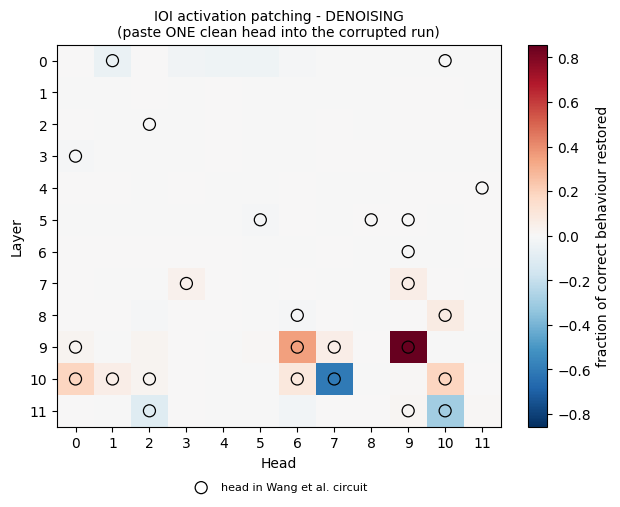

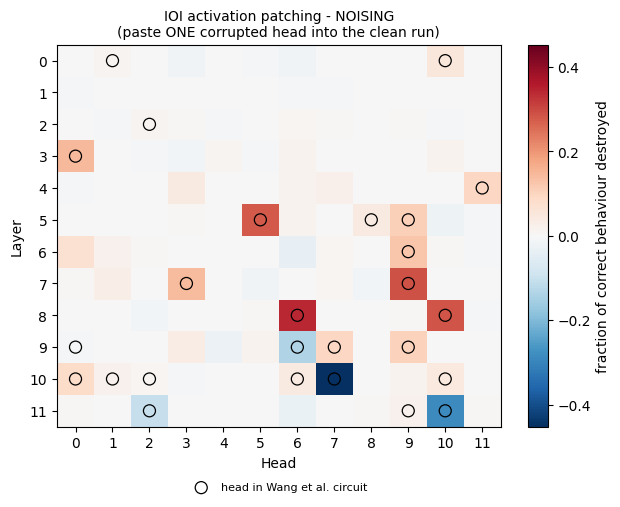

Top-10 heads, denoising : 9.9 (+0.86), 9.6 (+0.35), 10.10 (+0.19), 10.0 (+0.18), 10.6 (+0.09), 8.10 (+0.07), 10.1 (+0.06), 7.9 (+0.06), 9.7 (+0.05), 7.3 (+0.04)
Top-10 heads, noising   : 8.6 (+0.34), 7.9 (+0.29), 8.10 (+0.29), 5.5 (+0.28), 3.0 (+0.15), 7.3 (+0.14), 6.9 (+0.13), 5.9 (+0.11), 9.9 (+0.10), 4.11 (+0.09)


In [ ]:
RES = {"IOI (people)": {}}
R = RES["IOI (people)"]

R["denoise_raw"] = cached("ioi_denoise_raw", lambda: act_patch_raw(td_ioi, "denoise"))
R["noise_raw"]   = cached("ioi_noise_raw",   lambda: act_patch_raw(td_ioi, "noise"))
R["denoise"] = act_scores(td_ioi, R["denoise_raw"], "denoise")
R["noise"]   = act_scores(td_ioi, R["noise_raw"],   "noise")

plot_heatmap(R["denoise"], "IOI activation patching - DENOISING\n(paste ONE clean head into the corrupted run)",
             "fraction of correct behaviour restored", "ioi_act_patch_denoise")
plot_heatmap(R["noise"], "IOI activation patching - NOISING\n(paste ONE corrupted head into the clean run)",
             "fraction of correct behaviour destroyed", "ioi_act_patch_noise")

print("Top-10 heads, denoising :", fmt(top_heads(R["denoise"], 10)))
print("Top-10 heads, noising   :", fmt(top_heads(R["noise"], 10)))

### Path patching: tracing the circuit backwards (exactly Wang et al.'s procedure)

1. **Step A**: which heads act *directly* on the output? → expect **Name Mover** heads (strongly negative) and **Negative Name Movers** (positive).
2. **Step B**: which heads feed the Name Movers' *queries*? → expect **S-Inhibition** heads.
3. **Step C**: which heads feed the S-Inhibition heads' *values*? → expect **Duplicate Token / Induction / Previous-token** heads.

Reading the heatmaps: a value of `-40` means "patching this path removes 40% of the logit difference", i.e. the head strongly *supports* the right answer.

*Note on Step C:* the paper patches only at the `S2` position; here we patch all positions (simpler, qualitatively similar, numbers will differ a little).

[resumed] ioi_path_logits_raw  (loaded from checkpoint, nothing recomputed)


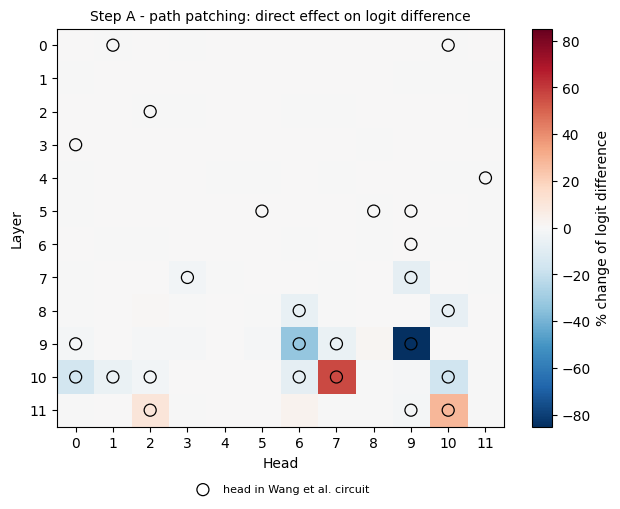

Found Name Movers          : [(9, 9), (9, 6), (10, 10)]    (paper: 9.9, 9.6, 10.0)
Found Negative Name Movers : [(10, 7), (11, 10)]    (paper: 10.7, 11.10)
[resumed] ioi_path_B_9-9_9-6_10-10  (loaded from checkpoint, nothing recomputed)


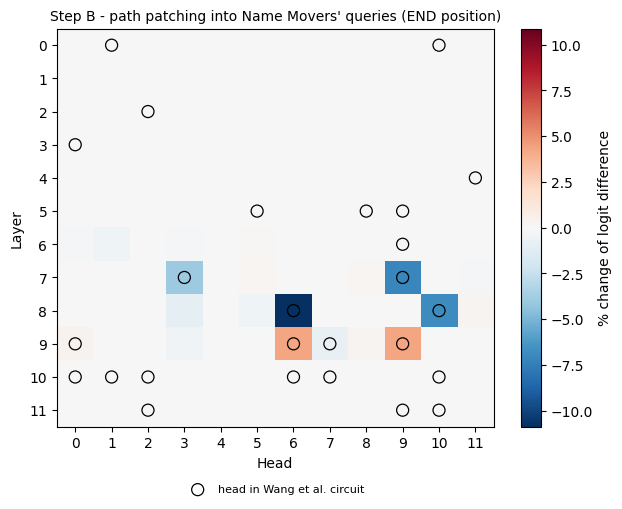

Found S-Inhibition heads   : [(8, 6), (7, 9), (8, 10), (7, 3)]    (paper: 7.3, 7.9, 8.6, 8.10)
[resumed] ioi_path_C_8-6_7-9_8-10_7-3  (loaded from checkpoint, nothing recomputed)


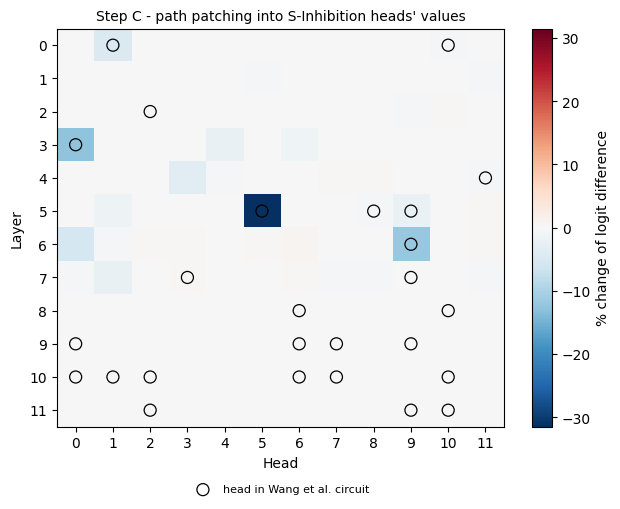

Found early heads (dup-token / induction / previous-token): [(5, 5), (3, 0), (6, 9), (6, 0), (0, 1), (4, 3)]
   paper: duplicate 0.1, 3.0 | induction 5.5, 6.9 | previous-token 2.2, 4.11

13 of the 15 heads we found are in Wang et al.'s 26-head circuit.


In [ ]:
# ---------------- Step A: direct effect on the logits ----------------
R["path_logits_raw"] = cached("ioi_path_logits_raw", lambda: path_patch_raw(td_ioi, None, "path patching -> logits"))
R["path_logits"] = path_pct(td_ioi, R["path_logits_raw"])
plot_heatmap(R["path_logits"], "Step A - path patching: direct effect on logit difference",
             "% change of logit difference", "ioi_path_A_logits")

name_movers = [hd for hd, _ in top_heads(R["path_logits"], 3, largest=False)]
neg_movers  = [hd for hd, _ in top_heads(R["path_logits"], 2, largest=True)]
print("Found Name Movers          :", name_movers, "   (paper: 9.9, 9.6, 10.0)")
print("Found Negative Name Movers :", neg_movers,  "   (paper: 10.7, 11.10)")

# ---------------- Step B: who feeds the Name Movers' queries? ----------------
recv_B = dict(kind="q", heads=name_movers, pos=-1)
R["path_B_raw"] = cached("ioi_path_B_" + heads_key(name_movers),
                         lambda: path_patch_raw(td_ioi, recv_B, "path patching -> NM queries"))
R["path_B"] = path_pct(td_ioi, R["path_B_raw"])
plot_heatmap(R["path_B"], "Step B - path patching into Name Movers' queries (END position)",
             "% change of logit difference", "ioi_path_B_nm_queries")
s_inhib = [hd for hd, _ in top_heads(R["path_B"], 4, largest=False)]
print("Found S-Inhibition heads   :", s_inhib, "   (paper: 7.3, 7.9, 8.6, 8.10)")

# ---------------- Step C: who feeds the S-Inhibition heads' values? ----------------
recv_C = dict(kind="v", heads=s_inhib, pos=slice(None))
R["path_C_raw"] = cached("ioi_path_C_" + heads_key(s_inhib),
                         lambda: path_patch_raw(td_ioi, recv_C, "path patching -> S-Inh values"))
R["path_C"] = path_pct(td_ioi, R["path_C_raw"])
plot_heatmap(R["path_C"], "Step C - path patching into S-Inhibition heads' values",
             "% change of logit difference", "ioi_path_C_sinh_values")
early = [hd for hd, _ in top_heads(R["path_C"], 6, largest=False)]
print("Found early heads (dup-token / induction / previous-token):", early)
print("   paper: duplicate 0.1, 3.0 | induction 5.5, 6.9 | previous-token 2.2, 4.11")

ref = set(REF_HEADS)
found = set(name_movers + neg_movers + s_inhib + early)
print(f"\n{len(found & ref)} of the {len(found)} heads we found are in Wang et al.'s 26-head circuit.")

In [ ]:
# ---------------- Unit tests: is the implementation correct? ----------------
# Test 1: for heads in the LAST layer nothing comes after them except MLP 11, so path patching
#         to the logits must equal plain noising activation patching. They are computed by
#         completely different code paths, so agreement is a strong correctness check.
assert np.allclose(R["noise_raw"][-1], R["path_logits_raw"][-1], atol=1e-3), "path vs activation patching mismatch!"
print("Test 1 passed: path patching == activation patching for last-layer heads")

# Test 2: if 'corrupted' activations equal clean ones, patching must change nothing.
g0 = td_ioi.groups[0]
g_same = replace(g0, corrupt_z=g0.clean_z)
diff = abs(_path_patch_one(g_same, n_layers // 2, n_heads // 2, None) - g0.ld_clean_sum)
assert diff < 1e-2, diff
print("Test 2 passed: patching clean into clean leaves the output unchanged")

# Test 3: the clean/corrupted gap must be real, otherwise the normalised scores are meaningless.
gap = td_ioi.ld_clean - td_ioi.ld_corrupt
if gap > 1.0:
    print(f"Test 3 passed: logit-diff gap clean-vs-corrupted = {gap:.2f}")
else:
    print(f"WARNING Test 3: gap clean-vs-corrupted is only {gap:.2f} (expected about 3.5 for GPT-2 small). "
          "Check the model loaded correctly before trusting any result below.")

Test 1 passed: path patching == activation patching for last-layer heads
Test 2 passed: patching clean into clean leaves the output unchanged
Test 3 passed: logit-diff gap clean-vs-corrupted = 3.62


In [ ]:
# ---------------- Part 4: assemble the circuit by role ----------------
rows = []
for role, heads in REF_ROLES.items():
    rows.append(dict(
        role=role,
        heads=" ".join(f"{l}.{h}" for l, h in heads),
        denoise=np.mean([R["denoise"][l, h] for l, h in heads]),
        noise=np.mean([R["noise"][l, h] for l, h in heads]),
        direct_effect_on_logits_pct=np.mean([R["path_logits"][l, h] for l, h in heads]),
    ))
circuit_table = pd.DataFrame(rows).round(3)
display(circuit_table)

others = [(l, h) for l in range(n_layers) for h in range(n_heads) if (l, h) not in set(REF_HEADS)]
print("Mean noising score  - circuit heads (26):",
      round(np.mean([R['noise'][l, h] for l, h in REF_HEADS]), 3),
      "| all other heads (118):", round(np.mean([R['noise'][l, h] for l, h in others]), 3))

# Whole-circuit test: noise ALL 26 circuit heads at once. How much of the behaviour dies?
print("Fraction of IOI behaviour destroyed by patching the 26-head circuit:",
      round(drop_fraction(td_ioi, REF_HEADS), 3))
circuit_table.to_csv(f"{OUT_DIR}/ioi_circuit_roles.csv", index=False)

,role,heads,denoise,noise,direct_effect_on_logits_pct
0,Name Mover,9.9 9.6 10.0,0.464,0.017,-44.571
1,Negative Name Mover,10.7 11.10,-0.450,-0.369,42.234
2,S-Inhibition,7.3 7.9 8.6 8.10,0.039,0.264,-5.649
3,Induction,5.5 5.8 5.9 6.9,-0.002,0.138,0.010
4,Duplicate Token,0.1 0.10 3.0,-0.022,0.070,-0.001
5,Previous Token,2.2 4.11,0.001,0.053,-0.042
6,Backup Name Mover,9.0 9.7 10.1 10.2 10.6 10.10 11.2 11.9,0.044,0.014,-3.915


Mean noising score  - circuit heads (26): 0.052 | all other heads (118): 0.001
Fraction of IOI behaviour destroyed by patching the 26-head circuit: 1.3


## Part 5: Generalization test (your original contribution)

**Question:** is the IOI circuit a narrow "names" trick, or a general **"two entities → one repeated → output the other"** mechanism?

We keep the *logical structure* identical to IOI but swap the entity type:

| Task | Example prompt → correct answer |
|---|---|
| IOI (people) | "Then, John and Mary went to the store. John gave a drink to" → ` Mary` |
| Animals | "After the cat and the dog met in the park, the cat looked at the" → ` dog` |
| Objects | "When the cup and the plate were on the table, someone picked up the cup and then looked at the" → ` plate` |
| Colors | "The red bag and the blue bag were in the garden. Then the red bag was moved next to the" → ` blue` |

**Important sanity check first:** patching only makes sense if GPT-2 *can* solve the new task. Look at the accuracy printed for each task. If a task is near 50% (chance), the model is not doing the task, and any "circuit" result for it is meaningless. Drop it or rewrite its templates.

For each task we measure:
1. **Rank correlation** of the 144-head importance map vs IOI (do the *same heads* matter?)
2. **Top-10 overlap** with IOI's top-10 heads
3. **Transfer ablation**: patch the IOI circuit's heads on the *new* task. If they matter there too, the circuit transfers. A random-heads baseline shows what "no transfer" looks like.

In [ ]:
GEN_TASKS = ["Animals", "Objects", "Colors", "Professions", "Fruits", "Vehicles", "Countries"]
TD = {"IOI (people)": td_ioi}
for name in GEN_TASKS:
    TD[name] = build_task(name, N_PROMPTS)
    RES[name] = {}

# (flag tasks the model cannot solve)
for name, td in TD.items():
    if td.acc < 0.7 or (td.ld_clean - td.ld_corrupt) < 0.5:
        print(f"WARNING: GPT-2 small is weak on '{name}' (acc={td.acc:.0%}). Treat its results with caution.")

[Animals] 100 prompts in 2 length-groups | logit diff clean=2.40  corrupted=-0.10 | accuracy (IO > S) = 96%
[Objects] 100 prompts in 3 length-groups | logit diff clean=1.80  corrupted=-0.19 | accuracy (IO > S) = 78%
[Colors] 100 prompts in 2 length-groups | logit diff clean=1.96  corrupted=-0.25 | accuracy (IO > S) = 94%
[Professions] 100 prompts in 2 length-groups | logit diff clean=1.73  corrupted=0.03 | accuracy (IO > S) = 74%
[Fruits] 100 prompts in 2 length-groups | logit diff clean=1.68  corrupted=0.23 | accuracy (IO > S) = 67%
[Vehicles] 100 prompts in 2 length-groups | logit diff clean=0.41  corrupted=-0.51 | accuracy (IO > S) = 56%
[Countries] 100 prompts in 7 length-groups | logit diff clean=2.14  corrupted=-0.04 | accuracy (IO > S) = 93%


[resumed] Animals_noise_raw  (loaded from checkpoint, nothing recomputed)
[resumed] Animals_path_logits_raw  (loaded from checkpoint, nothing recomputed)


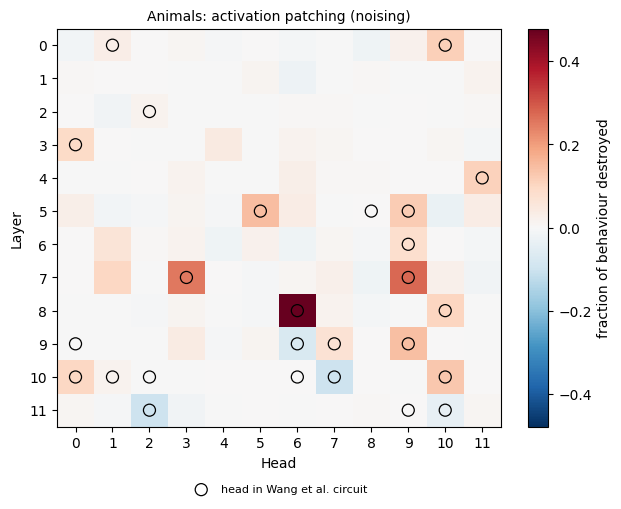

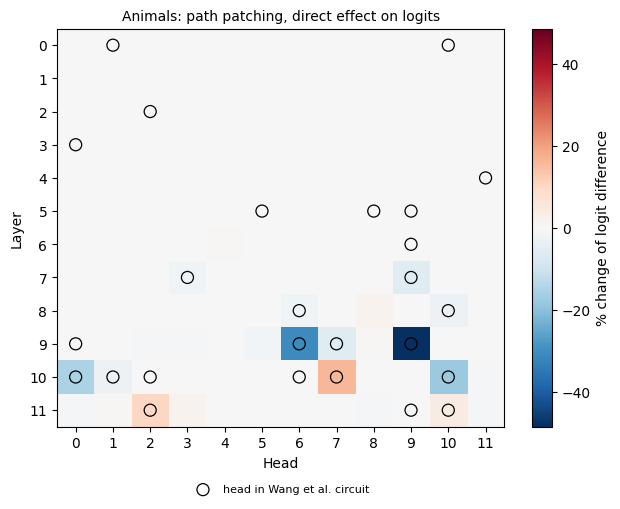

Animals  top-8 (noising): 8.6 (+0.48), 7.9 (+0.27), 7.3 (+0.25), 5.5 (+0.15), 9.9 (+0.15), 10.10 (+0.13), 5.9 (+0.12), 0.10 (+0.11)
[resumed] Objects_noise_raw  (loaded from checkpoint, nothing recomputed)
[resumed] Objects_path_logits_raw  (loaded from checkpoint, nothing recomputed)


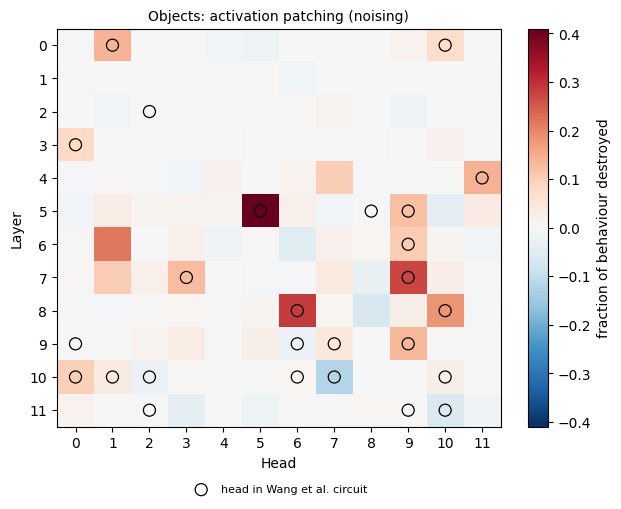

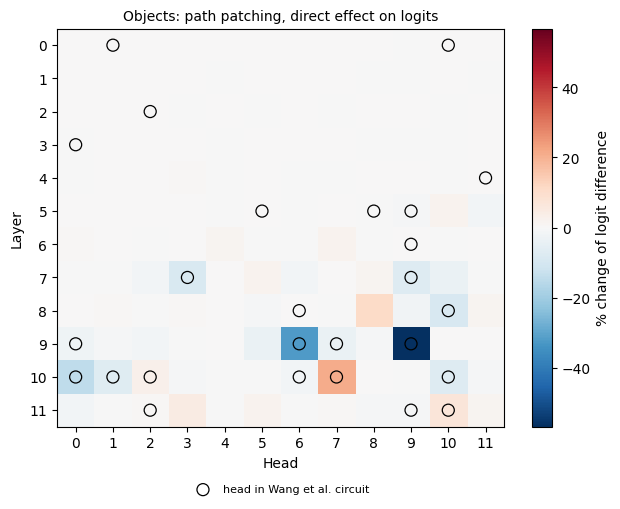

Objects  top-8 (noising): 5.5 (+0.41), 8.6 (+0.29), 7.9 (+0.27), 6.1 (+0.22), 8.10 (+0.18), 4.11 (+0.14), 0.1 (+0.14), 9.9 (+0.14)
[resumed] Colors_noise_raw  (loaded from checkpoint, nothing recomputed)
[resumed] Colors_path_logits_raw  (loaded from checkpoint, nothing recomputed)


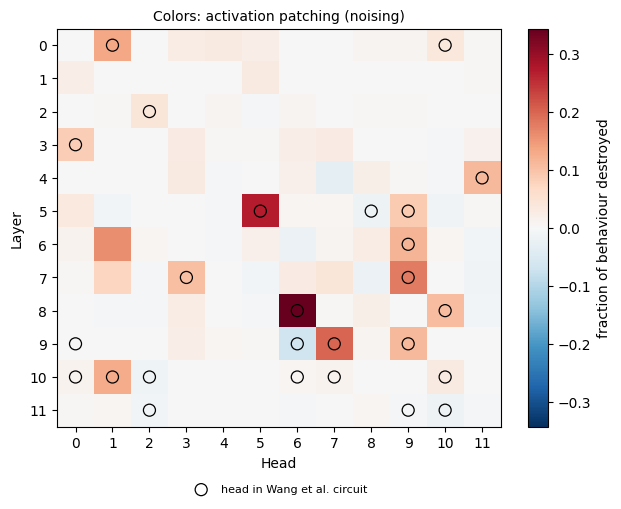

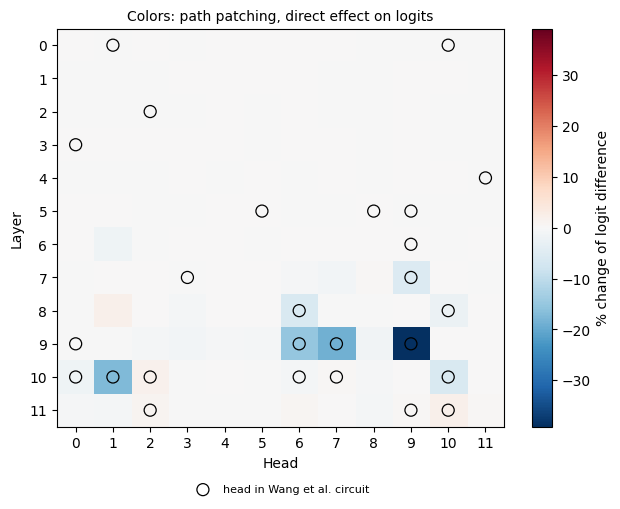

Colors   top-8 (noising): 8.6 (+0.34), 5.5 (+0.27), 9.7 (+0.20), 7.9 (+0.18), 6.1 (+0.16), 0.1 (+0.13), 10.1 (+0.13), 6.9 (+0.12)


activation patching (noise):   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Professions_noise_raw


Professions: path patching -> logits:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Professions_path_logits_raw


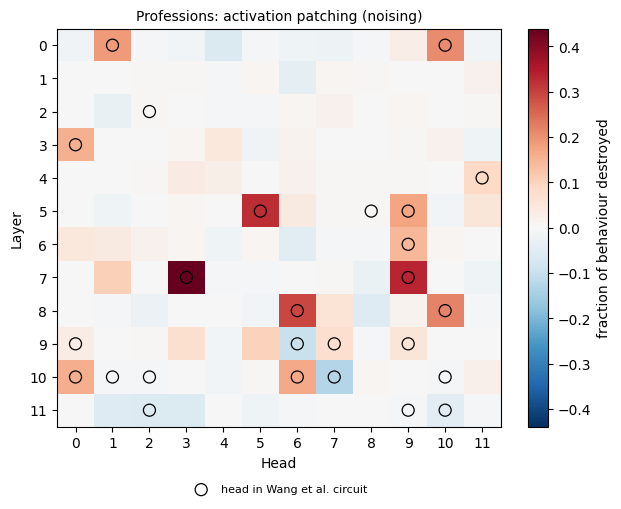

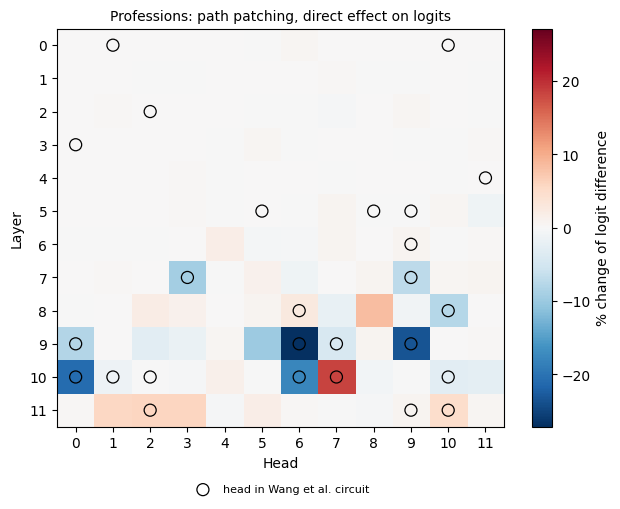

Professions top-8 (noising): 7.3 (+0.44), 7.9 (+0.34), 5.5 (+0.33), 8.6 (+0.29), 8.10 (+0.22), 0.10 (+0.21), 0.1 (+0.19), 5.9 (+0.17)


activation patching (noise):   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Fruits_noise_raw


Fruits: path patching -> logits:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Fruits_path_logits_raw


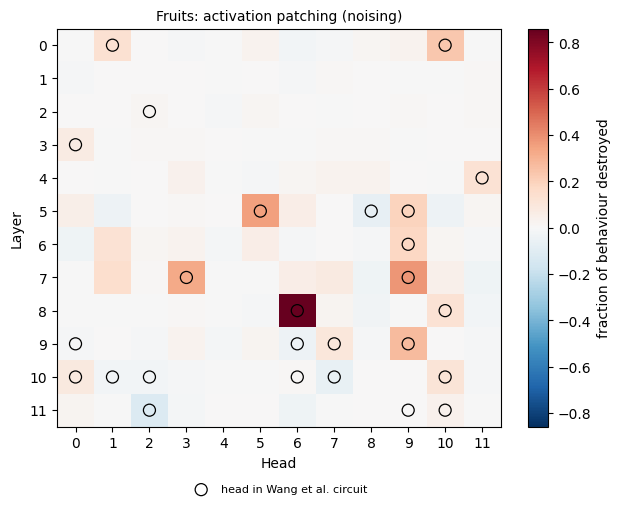

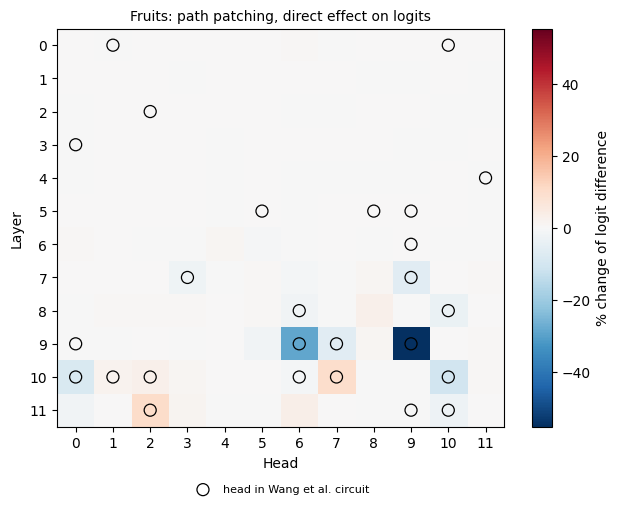

Fruits   top-8 (noising): 8.6 (+0.86), 7.9 (+0.38), 5.5 (+0.35), 7.3 (+0.33), 9.9 (+0.27), 0.10 (+0.23), 5.9 (+0.19), 6.9 (+0.18)


activation patching (noise):   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Vehicles_noise_raw


Vehicles: path patching -> logits:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Vehicles_path_logits_raw


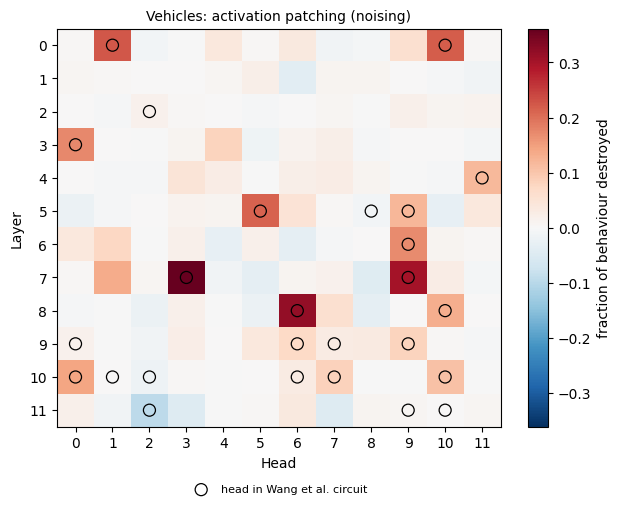

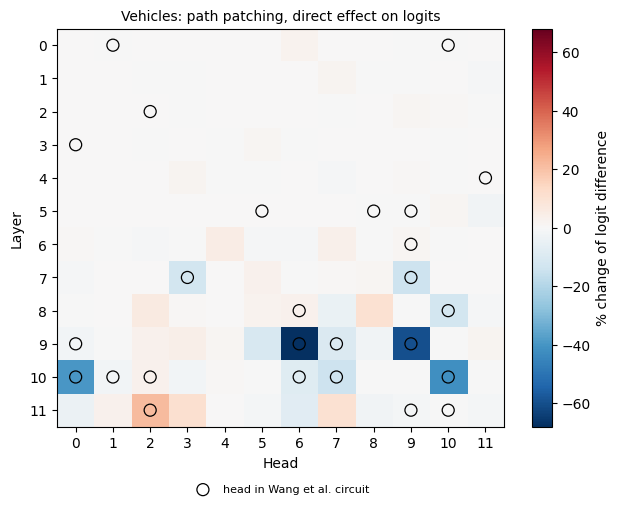

Vehicles top-8 (noising): 7.3 (+0.36), 8.6 (+0.32), 7.9 (+0.30), 0.1 (+0.22), 0.10 (+0.22), 5.5 (+0.21), 3.0 (+0.17), 6.9 (+0.17)


activation patching (noise):   0%|          | 0/7 [00:00<?, ?it/s]

[saved]   Countries_noise_raw


Countries: path patching -> logits:   0%|          | 0/7 [00:00<?, ?it/s]

[saved]   Countries_path_logits_raw


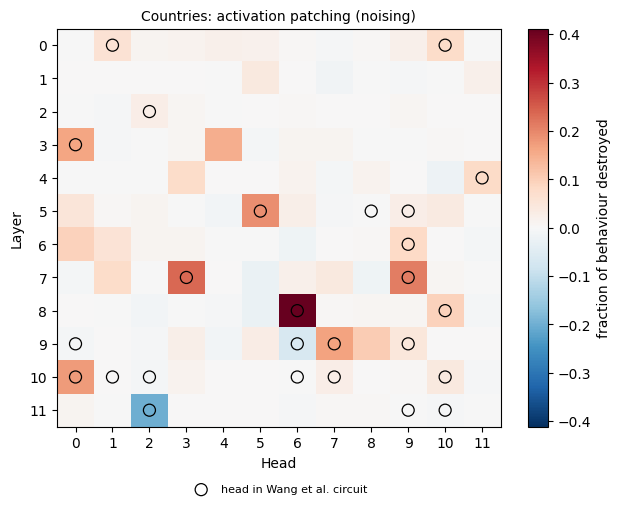

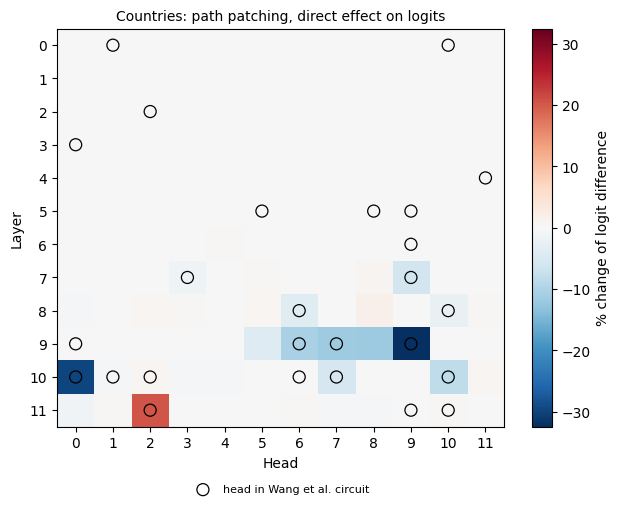

Countries top-8 (noising): 8.6 (+0.41), 7.3 (+0.23), 7.9 (+0.21), 5.5 (+0.19), 10.0 (+0.18), 9.7 (+0.16), 3.0 (+0.16), 3.4 (+0.15)
IOI      top-8 (noising): 8.6 (+0.34), 7.9 (+0.29), 8.10 (+0.29), 5.5 (+0.28), 3.0 (+0.15), 7.3 (+0.14), 6.9 (+0.13), 5.9 (+0.11)


In [ ]:
# ---- run the same two analyses on every generalization task ----
for name in GEN_TASKS:
    td, r = TD[name], RES[name]
    r["noise_raw"] = cached(f"{name}_noise_raw", lambda: act_patch_raw(td, "noise"))
    r["noise"]     = act_scores(td, r["noise_raw"], "noise")
    r["path_logits_raw"] = cached(f"{name}_path_logits_raw",
                                  lambda: path_patch_raw(td, None, f"{name}: path patching -> logits"))
    r["path_logits"]     = path_pct(td, r["path_logits_raw"])
    plot_heatmap(r["noise"], f"{name}: activation patching (noising)",
                 "fraction of behaviour destroyed", f"gen_{name.lower()}_noise")
    plot_heatmap(r["path_logits"], f"{name}: path patching, direct effect on logits",
                 "% change of logit difference", f"gen_{name.lower()}_path_logits")
    print(f"{name:8s} top-8 (noising):", fmt(top_heads(r["noise"], 8)))
print(f"{'IOI':8s} top-8 (noising):", fmt(top_heads(RES['IOI (people)']['noise'], 8)))

,task,accuracy,logit_diff_clean,rank_corr_vs_IOI,top10_overlap_with_IOI,drop_when_IOI_top10_patched,drop_when_10_RANDOM_heads_patched,drop_when_Wang_26_heads_patched
0,IOI (people),1.00,3.64,1.00,10,1.01,0.14,1.30
1,Animals,0.96,2.40,0.72,8,1.22,0.24,1.29
2,Objects,0.78,1.80,0.63,8,1.41,0.12,2.07
3,Colors,0.94,1.96,0.47,6,0.81,0.21,1.11
4,Professions,0.74,1.73,0.65,6,1.65,0.20,2.17
5,Fruits,0.67,1.68,0.54,7,1.71,0.30,1.54
6,Vehicles,0.56,0.41,0.48,6,1.40,0.27,1.95
7,Countries,0.93,2.14,0.51,5,0.96,0.19,1.37


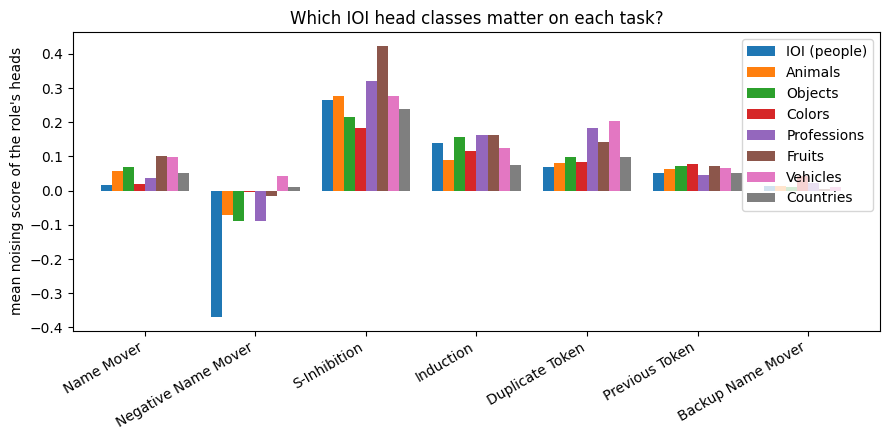

In [ ]:
# ---------------- Does the circuit transfer? ----------------
K = 10
ioi_top = [hd for hd, _ in top_heads(RES["IOI (people)"]["noise"], K)]
rng = random.Random(1)
all_heads = [(l, h) for l in range(n_layers) for h in range(n_heads)]

rows = []
for name, td in TD.items():
    r = RES[name]
    this_top = [hd for hd, _ in top_heads(r["noise"], K)]
    rand_drop = np.mean([drop_fraction(td, rng.sample(all_heads, K)) for _ in range(20)])
    rows.append({
        "task": name,
        "accuracy": round(td.acc, 2),
        "logit_diff_clean": round(td.ld_clean, 2),
        "rank_corr_vs_IOI": round(spearman(r["noise"], RES["IOI (people)"]["noise"]), 2),
        f"top{K}_overlap_with_IOI": len(set(this_top) & set(ioi_top)),
        f"drop_when_IOI_top{K}_patched": round(drop_fraction(td, ioi_top), 2),
        f"drop_when_{K}_RANDOM_heads_patched": round(float(rand_drop), 2),
        "drop_when_Wang_26_heads_patched": round(drop_fraction(td, REF_HEADS), 2),
    })
compare = pd.DataFrame(rows)
display(compare)
compare.to_csv(f"{OUT_DIR}/generalization_summary.csv", index=False)

# ---------------- role-level view (what you can put on a slide) ----------------
role_rows = {name: {role: np.mean([RES[name]["noise"][l, h] for l, h in hs])
                    for role, hs in REF_ROLES.items()} for name in TD}
role_df = pd.DataFrame(role_rows)
ax = role_df.plot.bar(figsize=(9, 4.5), width=0.8)
ax.set_ylabel("mean noising score of the role's heads"); ax.set_title("Which IOI head classes matter on each task?")
plt.xticks(rotation=30, ha="right"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/role_importance_by_task.png", dpi=200); plt.show()
role_df.round(3).to_csv(f"{OUT_DIR}/role_importance_by_task.csv")

### How to read the comparison table (and what to write in your report)

| Pattern in the table | Conclusion |
|---|---|
| High rank correlation, large top-10 overlap, IOI-top-10 patch destroys a **large** fraction of behaviour (≫ random baseline) | **Full transfer**: a general entity-tracking circuit |
| Name-Mover / S-Inhibition roles matter but others do not | **Partial transfer**: some sub-mechanisms are reused |
| Correlation near 0, patching IOI heads ≈ random baseline | **No transfer**: the circuit is IOI/names-specific |

All three outcomes are valid findings. Whatever you get, report it together with the accuracy column, since a task the model cannot solve cannot have a circuit.

**Limitations to state honestly** (panels like this): small template set; single-head patching can miss redundant/backup heads (Wang et al. found Backup Name Movers); patching is over all token positions; GPT-2 small only; MLPs are not analysed.

## Part 6: Is the circuit *sufficient*? (Wang et al.'s validation criteria)

Finding heads that matter is not the same as proving they are *the circuit*. Wang et al. test a circuit **C** against the full model **M** by **mean-ablating every head outside C** (replace it by its average activation on the corrupted "ABC" prompts) and asking how much of the behaviour survives. `F(X)` = mean logit difference when only the heads in `X` are active.

| Criterion | Question | Test |
|---|---|---|
| **Faithfulness** | Can C alone do the task as well as M? | `F(C)` vs `F(M)` |
| **Completeness** | Is anything important missing from C? | remove a subset K from both: `|F(C∖K) − F(M∖K)|` should stay small |
| **Minimality** | Does every head in C earn its place? | removing head v from C∖K should change F noticeably |

**Why this matters for your novelty:** `F(C)` can be evaluated on the *new* tasks too. If keeping **only the 26 IOI heads** (and ablating everything else) still lets GPT-2 solve Animals / Objects / Colors, that is direct evidence that the circuit *transfers*, far stronger than comparing heatmaps. We compare against **20 random 26-head sets** as the "no special circuit" baseline and give bootstrap 95% confidence intervals.

*Approximation:* the mean activation is taken over each batch of equal-length prompts (Wang et al. average per template and per position-role), and heads are kept/removed at all positions. Treat absolute numbers as slightly different from the paper.

In [ ]:
ALL_HEADS = [(l, h) for l in range(n_layers) for h in range(n_heads)]

def _meanabl_hook(z, hook, heads, mean):
    z[:, :, heads, :] = mean[:, :, heads, :]
    return z

def _ensure_means(td):
    for g in td.groups:
        if getattr(g, "mean_z", None) is None:
            g.mean_z = [z.mean(0, keepdim=True) for z in g.corrupt_z]   # mean over the ABC prompts

def F(td, keep, per_prompt=False):
    """logit difference when ONLY the heads in `keep` are active (all other heads mean-ablated)"""
    _ensure_means(td)
    keep, vals = set(keep), []
    for g in td.groups:
        hooks = []
        for l in range(n_layers):
            abl = [h for h in range(n_heads) if (l, h) not in keep]
            if abl:
                hooks.append((utils.get_act_name("z", l), partial(_meanabl_hook, heads=abl, mean=g.mean_z[l])))
        vals.append(ld_per_prompt(model.run_with_hooks(g.clean, fwd_hooks=hooks), g))
    vals = torch.cat(vals).cpu().numpy()
    return vals if per_prompt else float(vals.mean())

# unit test: keeping every head must reproduce the normal clean run
assert abs(F(td_ioi, ALL_HEADS) - td_ioi.ld_clean) < 1e-3
print("Test 4 passed: keeping all heads reproduces the clean run")

# "Discovered" circuit = heads found by our own path patching (steps A-C) + top noising heads, padded to 26
disc = []
for hd in name_movers + neg_movers + s_inhib + early:
    if hd not in disc: disc.append(hd)
for hd, _ in top_heads(RES["IOI (people)"]["noise"], 80):
    if len(disc) >= 26: break
    if hd not in disc: disc.append(hd)
DISC = disc[:26]
RAND_SETS = [random.Random(100 + i).sample(ALL_HEADS, 26) for i in range(20)]

def boot_ratio_ci(num, den, B=2000, seed=0):
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(num), (B, len(num)))
    r = num[idx].mean(1) / den[idx].mean(1)
    return np.percentile(r, [2.5, 97.5])

rows = []
for name, td in TD.items():
    pm = F(td, ALL_HEADS, True)                    # full model, per prompt
    pw = F(td, REF_HEADS, True)                    # Wang's published 26 heads only
    pdc = F(td, DISC, True)                        # our discovered 26 heads only
    rnd = np.mean([F(td, s) for s in RAND_SETS]) / pm.mean()
    lo, hi = boot_ratio_ci(pw, pm)
    RES[name]["retained_wang"], RES[name]["retained_rand"] = float(pw.mean() / pm.mean()), float(rnd)
    rows.append({"task": name, "F(full model)": round(pm.mean(), 2),
                 "retained: Wang 26 heads": f"{pw.mean()/pm.mean():.2f}  [{lo:.2f}, {hi:.2f}]",
                 "retained: our 26 heads": round(pdc.mean() / pm.mean(), 2),
                 "retained: 20 random 26-sets": round(rnd, 2)})
faith = pd.DataFrame(rows)
display(faith)
faith.to_csv(f"{OUT_DIR}/faithfulness_and_transfer.csv", index=False)
print("retained = F(circuit only) / F(full model). 1.0 = the circuit alone does the whole task; 0 = nothing survives.")

Test 4 passed: keeping all heads reproduces the clean run


,task,F(full model),retained: Wang 26 heads,retained: our 26 heads,retained: 20 random 26-sets
0,IOI (people),3.64,"0.84 [0.76, 0.93]",1.05,-0.08
1,Animals,2.40,"0.41 [0.30, 0.50]",0.64,-0.17
2,Objects,1.80,"0.63 [0.51, 0.74]",0.81,-0.36
3,Colors,1.96,"0.45 [0.36, 0.54]",0.48,-0.05
4,Professions,1.73,"0.62 [0.48, 0.74]",0.90,-0.30
5,Fruits,1.68,"0.28 [0.11, 0.43]",0.64,-0.18
6,Vehicles,0.41,"0.16 [-1.29, 0.91]",0.80,-1.36
7,Countries,2.14,"0.49 [0.41, 0.58]",0.82,-0.17


retained = F(circuit only) / F(full model). 1.0 = the circuit alone does the whole task; 0 = nothing survives.


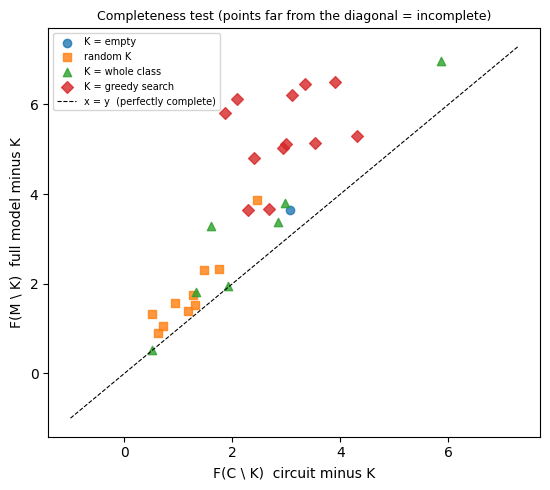

max incompleteness, K = empty         :  15.5% of F(M)
max incompleteness, random K          :  39.0% of F(M)
max incompleteness, K = whole class   :  46.0% of F(M)
max incompleteness, K = greedy search : 110.9% of F(M)
(Wang et al. also found the greedy search exposes incompleteness, up to ~87% of F(M).)


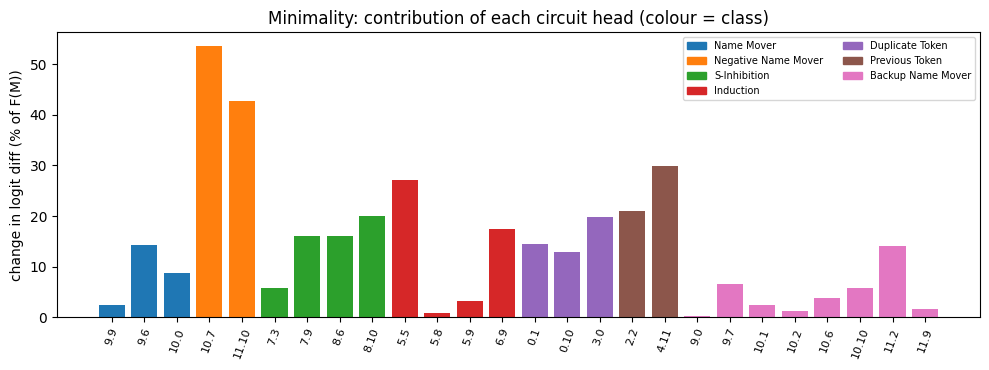

heads contributing < 1% of F(M): ['5.8', '9.0']


In [ ]:
# ---------------- Completeness + minimality, on the IOI task with Wang's circuit ----------------
td, fm = td_ioi, td_ioi.ld_clean
def inc_pt(K):
    Ks = set(K)
    return (F(td, [x for x in REF_HEADS if x not in Ks]), F(td, [x for x in ALL_HEADS if x not in Ks]))

rng = random.Random(3)
pts = {"K = empty": [inc_pt([])],
       "random K": [inc_pt(rng.sample(REF_HEADS, rng.randint(1, 13))) for _ in range(10)],
       "K = whole class": [inc_pt(hs) for hs in REF_ROLES.values()]}

def greedy(steps=6, k=6, seed=0):
    r, K, trace = random.Random(seed), [], []
    for _ in range(steps):
        best = None
        for v in r.sample([x for x in REF_HEADS if x not in K], k):
            c, m = inc_pt(K + [v])
            if best is None or abs(c - m) > abs(best[1] - best[2]): best = (v, c, m)
        K.append(best[0]); trace.append((best[1], best[2]))
    return trace
pts["K = greedy search"] = greedy(seed=0) + greedy(seed=1)

fig, ax = plt.subplots(figsize=(5.6, 5))
for (label, P), mk in zip(pts.items(), ["o", "s", "^", "D"]):
    ax.scatter([p[0] for p in P], [p[1] for p in P], marker=mk, label=label, alpha=0.8)
lim = [min(-1, ax.get_xlim()[0], ax.get_ylim()[0]), max(ax.get_xlim()[1], ax.get_ylim()[1])]
ax.plot(lim, lim, "k--", lw=0.8, label="x = y  (perfectly complete)")
ax.set_xlabel("F(C \\ K)  circuit minus K"); ax.set_ylabel("F(M \\ K)  full model minus K")
ax.set_title("Completeness test (points far from the diagonal = incomplete)", fontsize=9); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/completeness.png", dpi=200); plt.show()
for label, P in pts.items():
    print(f"max incompleteness, {label:18s}: {max(abs(c-m) for c, m in P)/fm*100:5.1f}% of F(M)")
print("(Wang et al. also found the greedy search exposes incompleteness, up to ~87% of F(M).)")

# ---- minimality: remove ONE head v from C after removing the rest of its class ----
rows = []
for role, hs in REF_ROLES.items():
    for v in hs:
        K = [x for x in hs if x != v]
        base = F(td, [x for x in REF_HEADS if x not in K])
        without = F(td, [x for x in REF_HEADS if x not in K and x != v])
        rows.append({"role": role, "head": f"{v[0]}.{v[1]}", "minimality_pct_of_FM": abs(without - base) / fm * 100})
minimal = pd.DataFrame(rows)
colors = dict(zip(REF_ROLES, plt.cm.tab10.colors))
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.bar(range(len(minimal)), minimal.minimality_pct_of_FM, color=[colors[r] for r in minimal.role])
ax.set_xticks(range(len(minimal))); ax.set_xticklabels(minimal["head"], rotation=70, fontsize=8)
ax.set_ylabel("change in logit diff (% of F(M))"); ax.set_title("Minimality: contribution of each circuit head (colour = class)")
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()], labels=list(colors), fontsize=7, ncol=2)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/minimality.png", dpi=200); plt.show()
print("heads contributing < 1% of F(M):", list(minimal[minimal.minimality_pct_of_FM < 1]["head"]))
minimal.to_csv(f"{OUT_DIR}/minimality.csv", index=False)

## Part 7: Do the heads still *behave* like their roles on the new tasks?

Patching tells us a head *matters*; attention patterns tell us *what it does*. Wang et al. identified the roles by behaviour, and we can test the same behaviours on every task:

| Role | Behaviour to test (measured on clean prompts) |
|---|---|
| **Name Mover** | at the last token, attends to the **correct entity (IO)** rather than the repeated one (S1/S2). Paper: ≈0.59 attention on IO |
| **S-Inhibition** | at the last token, attends to the **second mention (S2)** (paper: ≈0.51) |
| **Duplicate Token** | at S2, attends back to **S1** |
| **Induction** | at S2, attends to the token **after S1** |

If Name Movers keep attending to the correct entity on Animals / Objects / Colors, the *mechanism* transfers, not just the heatmap.

  (Objects: skipped 2 prompts whose entity tokens repeat unexpectedly)


,NameMover: attn to IO (correct),NameMover: attn to S1,NameMover: attn to S2,S-Inhibition: attn to S2,DuplicateToken: S2->S1,Induction: S2->S1+1
IOI (people),0.590,0.108,0.027,0.457,0.520,0.411
Animals,0.364,0.077,0.035,0.367,0.442,0.311
Objects,0.298,0.076,0.020,0.267,0.372,0.280
Colors,0.308,0.078,0.022,0.265,0.399,0.456
Professions,0.294,0.088,0.037,0.272,0.437,0.343
Fruits,0.254,0.069,0.021,0.263,0.439,0.391
Vehicles,0.166,0.073,0.024,0.219,0.392,0.291
Countries,0.330,0.094,0.042,0.288,0.449,0.315


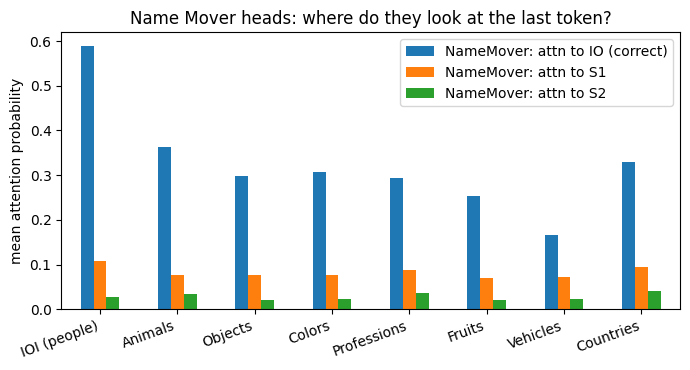

Paper (IOI): Name Movers attend IO ~0.59; S-Inhibition attend S2 ~0.51.


In [ ]:
ATTN_METRICS = ["to_IO", "to_S1", "to_S2", "S2_to_S1", "S2_to_S1plus1"]

def _positions(g):
    """token positions of IO (once), S1 and S2 (the two mentions of the repeated entity)"""
    L = g.clean.shape[1]
    ar = torch.arange(L, device=g.clean.device)[None, :].expand_as(g.clean)
    eq_s, eq_io = g.clean == g.s[:, None], g.clean == g.io[:, None]
    valid = (eq_s.sum(1) == 2) & (eq_io.sum(1) == 1)
    s1 = torch.where(eq_s, ar, torch.full_like(ar, L)).min(1).values
    s2 = torch.where(eq_s, ar, torch.full_like(ar, -1)).max(1).values
    io = torch.where(eq_io, ar, torch.full_like(ar, -1)).max(1).values
    return io, s1, s2, valid

def role_attention(td):
    store = {hd: {k: [] for k in ATTN_METRICS} for hd in REF_HEADS}
    dropped = 0
    for g in td.groups:
        io, s1, s2, valid = _positions(g)
        dropped += int((~valid).sum())
        if int(valid.sum()) == 0: continue
        _, cache = model.run_with_cache(g.clean, names_filter=lambda n: n.endswith("attn.hook_pattern"))
        io, s1, s2 = io[valid], s1[valid], s2[valid]
        bb = torch.arange(len(io), device=io.device)
        for (l, h) in REF_HEADS:
            p = cache[utils.get_act_name("pattern", l)][valid, h]          # [b, query, key]
            end = p[:, -1, :]                                               # attention FROM the last token
            vals = [end[bb, io], end[bb, s1], end[bb, s2], p[bb, s2, s1], p[bb, s2, s1 + 1]]
            for k, v in zip(ATTN_METRICS, vals):
                store[(l, h)][k] += v.tolist()
    if dropped: print(f"  ({td.name}: skipped {dropped} prompts whose entity tokens repeat unexpectedly)")
    rows = []
    for role, hs in REF_ROLES.items():
        row = {"role": role}
        for k in ATTN_METRICS:
            row[k] = float(np.mean([np.mean(store[hd][k]) for hd in hs]))
        rows.append(row)
    return pd.DataFrame(rows).set_index("role")

ATT = {name: role_attention(td) for name, td in TD.items()}
att_all = pd.concat(ATT, names=["task"])
att_all.round(3).to_csv(f"{OUT_DIR}/role_attention.csv")

key = pd.DataFrame({
    "NameMover: attn to IO (correct)":  {t: ATT[t].loc["Name Mover", "to_IO"] for t in TD},
    "NameMover: attn to S1":            {t: ATT[t].loc["Name Mover", "to_S1"] for t in TD},
    "NameMover: attn to S2":            {t: ATT[t].loc["Name Mover", "to_S2"] for t in TD},
    "S-Inhibition: attn to S2":         {t: ATT[t].loc["S-Inhibition", "to_S2"] for t in TD},
    "DuplicateToken: S2->S1":           {t: ATT[t].loc["Duplicate Token", "S2_to_S1"] for t in TD},
    "Induction: S2->S1+1":              {t: ATT[t].loc["Induction", "S2_to_S1plus1"] for t in TD},
})
display(key.round(3))
key.round(3).to_csv(f"{OUT_DIR}/role_behaviour_key_table.csv")
key.iloc[:, :3].plot.bar(figsize=(7, 3.8)); plt.ylabel("mean attention probability")
plt.title("Name Mover heads: where do they look at the last token?"); plt.xticks(rotation=20, ha="right")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/name_mover_attention.png", dpi=200); plt.show()
print("Paper (IOI): Name Movers attend IO ~0.59; S-Inhibition attend S2 ~0.51.")

Animals: path patching -> NM queries:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Animals_path_B_9-9_9-6_10-10


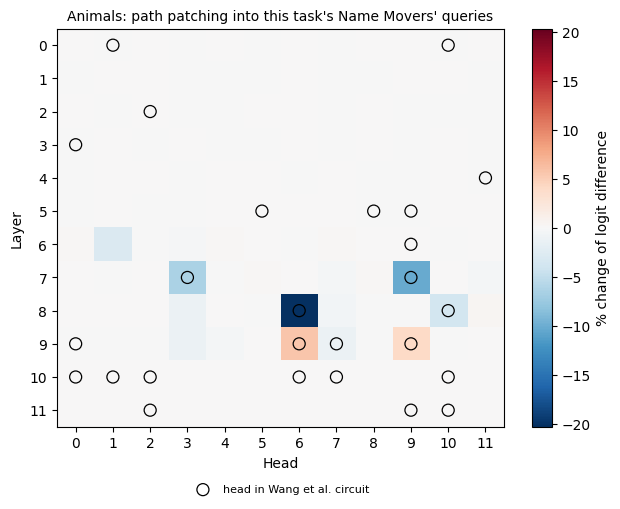

Objects: path patching -> NM queries:   0%|          | 0/3 [00:00<?, ?it/s]

[saved]   Objects_path_B_9-9_9-6_10-0


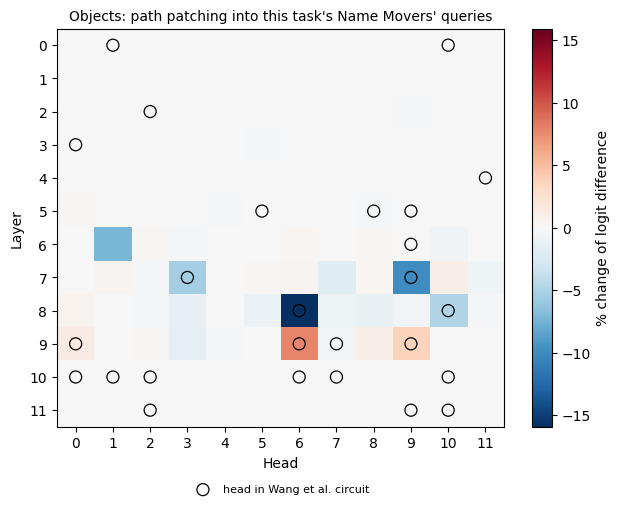

Colors: path patching -> NM queries:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Colors_path_B_9-9_9-7_10-1


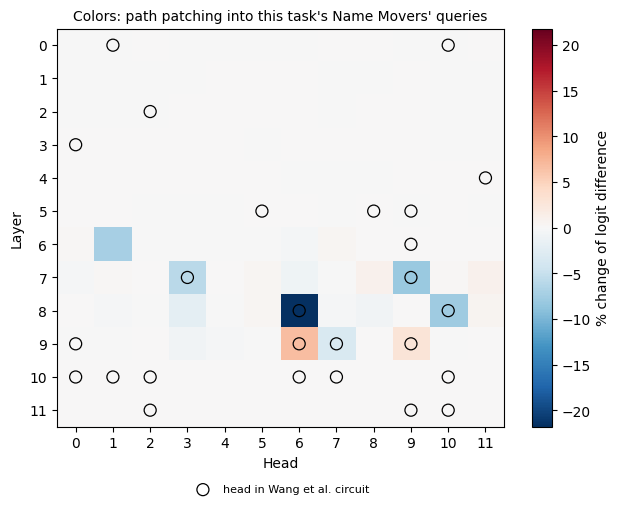

Professions: path patching -> NM queries:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Professions_path_B_9-6_9-9_10-0


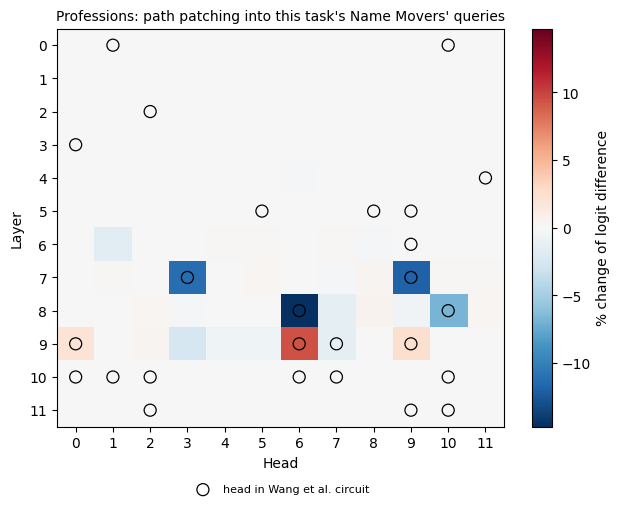

Fruits: path patching -> NM queries:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Fruits_path_B_9-9_9-6_10-10


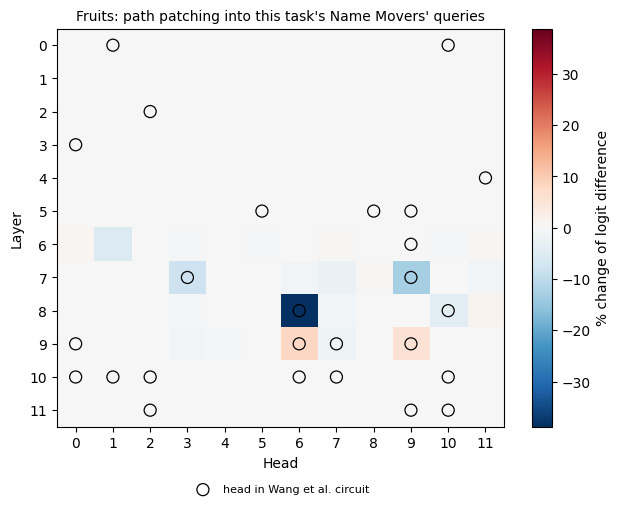

Vehicles: path patching -> NM queries:   0%|          | 0/2 [00:00<?, ?it/s]

[saved]   Vehicles_path_B_9-6_9-9_10-10


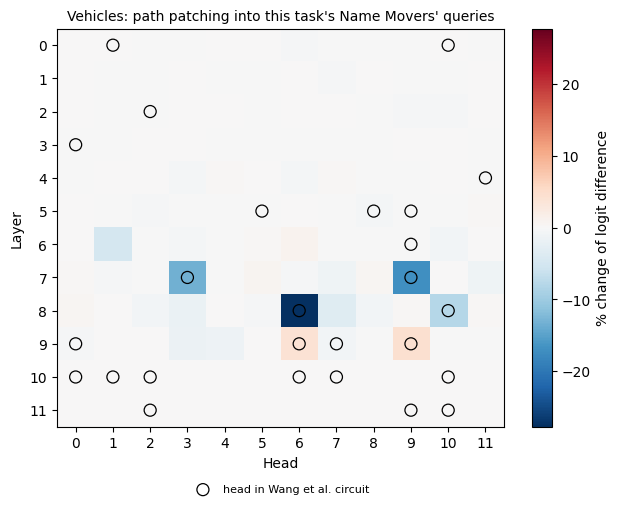

Countries: path patching -> NM queries:   0%|          | 0/7 [00:00<?, ?it/s]

[saved]   Countries_path_B_9-9_10-0_9-8


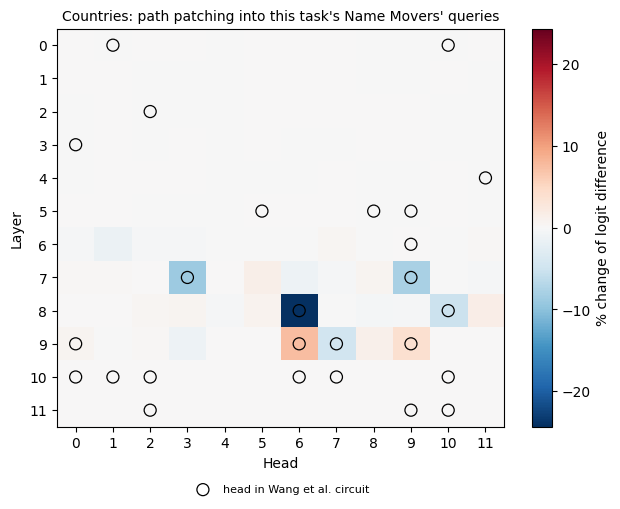

,task,Name Movers found,S-Inhibition found,NM overlap with IOI (Jaccard),S-Inh overlap with IOI (Jaccard)
0,IOI (people),9.9 9.6 10.10,8.6 7.9 8.10 7.3,1.0,1.0
1,Animals,9.9 9.6 10.10,8.6 7.9 7.3 8.10,1.0,1.0
2,Objects,9.9 9.6 10.0,8.6 7.9 6.1 7.3,0.5,0.6
3,Colors,9.9 9.7 10.1,8.6 7.9 8.10 6.1,0.2,0.6
4,Professions,9.6 9.9 10.0,8.6 7.9 7.3 8.10,0.5,1.0
5,Fruits,9.9 9.6 10.10,8.6 7.9 7.3 6.1,1.0,0.6
6,Vehicles,9.6 9.9 10.10,8.6 7.9 7.3 8.10,1.0,1.0
7,Countries,9.9 10.0 9.8,8.6 7.3 7.9 8.10,0.2,1.0


,task,rank_corr_vs_IOI,permutation_p
0,Animals,0.723,0.0003
1,Objects,0.631,0.0003
2,Colors,0.470,0.0003
3,Professions,0.652,0.0003
4,Fruits,0.544,0.0003
5,Vehicles,0.478,0.0003
6,Countries,0.510,0.0003


(Head maps are partly similar for generic reasons, e.g. late layers matter more, so read rho together with Parts 6-8.)


In [ ]:
# ---- Part 8: re-DISCOVER the circuit on each new task (path patching steps A and B) ----
RES["IOI (people)"]["name_movers"] = name_movers
RES["IOI (people)"]["s_inhib"] = s_inhib

for name in GEN_TASKS:
    td, r = TD[name], RES[name]
    nm = [hd for hd, _ in top_heads(r["path_logits"], 3, largest=False)]
    recv = dict(kind="q", heads=nm, pos=-1)
    r["path_B_raw"] = cached(f"{name}_path_B_" + heads_key(nm),
                             lambda: path_patch_raw(td, recv, f"{name}: path patching -> NM queries"))
    r["path_B"] = path_pct(td, r["path_B_raw"])
    r["name_movers"] = nm
    r["s_inhib"] = [hd for hd, _ in top_heads(r["path_B"], 4, largest=False)]
    plot_heatmap(r["path_B"], f"{name}: path patching into this task's Name Movers' queries",
                 "% change of logit difference", f"gen_{name.lower()}_path_B")

def jaccard(a, b): return len(set(a) & set(b)) / max(1, len(set(a) | set(b)))
rows = []
for name in TD:
    r = RES[name]
    rows.append({"task": name,
                 "Name Movers found": " ".join(f"{l}.{h}" for l, h in r["name_movers"]),
                 "S-Inhibition found": " ".join(f"{l}.{h}" for l, h in r["s_inhib"]),
                 "NM overlap with IOI (Jaccard)": round(jaccard(r["name_movers"], RES["IOI (people)"]["name_movers"]), 2),
                 "S-Inh overlap with IOI (Jaccard)": round(jaccard(r["s_inhib"], RES["IOI (people)"]["s_inhib"]), 2)})
disc_tbl = pd.DataFrame(rows)
display(disc_tbl)
disc_tbl.to_csv(f"{OUT_DIR}/rediscovered_roles.csv", index=False)

# ---- Statistics: is the head-importance correlation more than chance? (permutation test) ----
def perm_test(a, b, n=3000, seed=0):
    rng = np.random.default_rng(seed); obs = spearman(a, b); bf = b.ravel().copy(); cnt = 0
    for _ in range(n):
        rng.shuffle(bf); cnt += spearman(a, bf) >= obs
    return obs, (cnt + 1) / (n + 1)
rows = []
for name in GEN_TASKS:
    rho, p = perm_test(RES["IOI (people)"]["noise"], RES[name]["noise"])
    RES[name]["rho"], RES[name]["rho_p"] = rho, p
    rows.append({"task": name, "rank_corr_vs_IOI": round(rho, 3), "permutation_p": round(p, 4)})
perm_tbl = pd.DataFrame(rows); display(perm_tbl)
perm_tbl.to_csv(f"{OUT_DIR}/rank_corr_permutation_test.csv", index=False)
print("(Head maps are partly similar for generic reasons, e.g. late layers matter more, so read rho together with Parts 6-8.)")

In [ ]:
# ---------------- Automatic summary of the evidence (edit the wording for your report) ----------------
print("=" * 78); print("EVIDENCE SUMMARY"); print("=" * 78)
ioi = RES["IOI (people)"]
print(f"[Reproduction] IOI accuracy {td_ioi.acc:.0%}, logit diff {td_ioi.ld_clean:.2f} (paper 3.56). "
      f"Found Name Movers {name_movers}, S-Inhibition {s_inhib}.")
print(f"[Sufficiency ] Wang's 26 heads alone retain {ioi['retained_wang']:.0%} of IOI performance "
      f"(20 random 26-sets: {ioi['retained_rand']:.0%}).\n")
for name in GEN_TASKS:
    r = RES[name]; a = ATT[name]
    nm_io, nm_s = a.loc["Name Mover", "to_IO"], a.loc["Name Mover", "to_S1"] + a.loc["Name Mover", "to_S2"]
    score = (r["retained_wang"] >= 0.5 and r["retained_wang"] >= 2 * max(r["retained_rand"], 0.05)) + \
            (nm_io > nm_s) + (r["rho_p"] < 0.01 and r["rho"] > 0.3) + \
            (len(set(r["name_movers"]) & set(ioi["name_movers"])) >= 2)
    verdict = {4: "FULL transfer", 3: "STRONG partial transfer", 2: "PARTIAL transfer",
               1: "WEAK transfer", 0: "NO transfer"}[int(score)]
    print(f"{name:8s} -> {verdict}  ({int(score)}/4 criteria)")
    print(f"   circuit-only retains {r['retained_wang']:.0%} (random {r['retained_rand']:.0%}) | "
          f"Name Movers look at the correct entity: {nm_io:.2f} vs {nm_s:.2f} on repeated one | "
          f"rank-corr {r['rho']:.2f} (p={r['rho_p']:.3f}) | NMs found: {r['name_movers']}")
print("\nCriteria (heuristic, state them in your report): (1) IOI circuit alone keeps >=50% of performance and >=2x random;"
      "\n(2) Name Movers attend the correct entity more than the repeated one; (3) head-importance rank correlation with IOI"
      "\nsignificant (p<0.01, rho>0.3); (4) >=2 of IOI's 3 Name Movers re-discovered on the new task.")

EVIDENCE SUMMARY
[Reproduction] IOI accuracy 100%, logit diff 3.64 (paper 3.56). Found Name Movers [(9, 9), (9, 6), (10, 10)], S-Inhibition [(8, 6), (7, 9), (8, 10), (7, 3)].
[Sufficiency ] Wang's 26 heads alone retain 84% of IOI performance (20 random 26-sets: -8%).

Animals  -> WEAK transfer  (1/4 criteria)
   circuit-only retains 41% (random -17%) | Name Movers look at the correct entity: 0.36 vs 0.11 on repeated one | rank-corr 0.72 (p=0.000) | NMs found: [(9, 9), (9, 6), (10, 10)]
Objects  -> WEAK transfer  (1/4 criteria)
   circuit-only retains 63% (random -36%) | Name Movers look at the correct entity: 0.30 vs 0.10 on repeated one | rank-corr 0.63 (p=0.000) | NMs found: [(9, 9), (9, 6), (10, 0)]
Colors   -> WEAK transfer  (1/4 criteria)
   circuit-only retains 45% (random -5%) | Name Movers look at the correct entity: 0.31 vs 0.10 on repeated one | rank-corr 0.47 (p=0.000) | NMs found: [(9, 9), (9, 7), (10, 1)]
Professions -> WEAK transfer  (1/4 criteria)
   circuit-only retains

## Part 9: What *predicts* whether the circuit transfers? (exploratory analysis)

With several task families we can ask a question that goes beyond "does it transfer on task X": **which property of a task predicts transfer?**

Hypothesis tested here: *the closer a task's entities are to person names in the model's embedding space, the more of the IOI circuit is reused.* For each family we compute

- **semantic distance to names** = 1 − mean cosine similarity between the family's entity-token embeddings and the name-token embeddings (`W_E`),
- **baseline difficulty** = clean logit difference of the model on the task,

and relate both to **retained fraction** (Part 6: performance kept when only the IOI circuit is active).

*Be honest in the paper:* with ~7 families this is **exploratory** (low statistical power). Report the correlation, its permutation p-value and the scatter plot, and say so.

,semantic_distance_to_names,baseline_logit_diff,accuracy,retained_IOI_circuit,retained_random,rank_corr_vs_IOI
task,,,,,,
Animals,0.756,2.405,0.96,0.407,-0.170,0.723
Objects,0.775,1.798,0.78,0.631,-0.358,0.631
Colors,0.764,1.955,0.94,0.452,-0.054,0.470
Professions,0.746,1.732,0.74,0.617,-0.298,0.652
Fruits,0.749,1.685,0.67,0.278,-0.176,0.544
Vehicles,0.776,0.407,0.56,0.159,-1.363,0.478
Countries,0.747,2.145,0.93,0.488,-0.174,0.510


semantic_distance_to_names   vs retained: rho=-0.32  p=0.498
baseline_logit_diff          vs retained: rho=+0.36  p=0.451


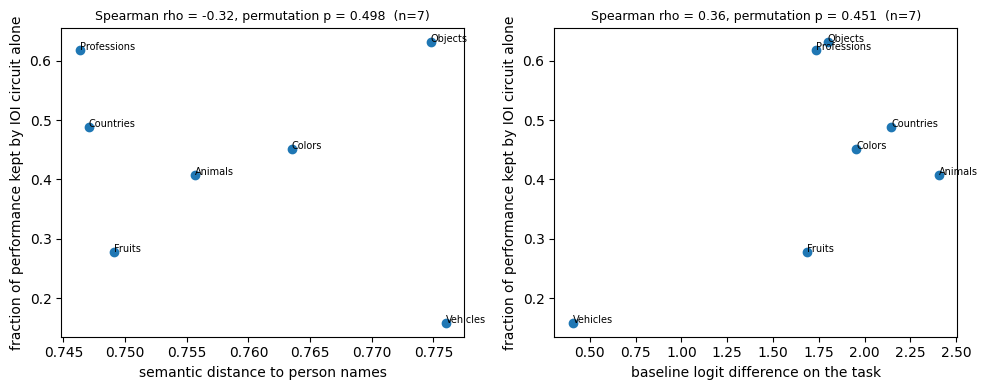

Exploratory: n is small. Report effect size and p-value, and do not over-claim.


In [ ]:
def entity_embedding(name):
    words = [w for w in TASKS[name]["pool"] if is_single_token(" " + w)]
    E = torch.stack([model.W_E[tok(w)] for w in words]).float()
    return torch.nn.functional.normalize(E, dim=-1)

E_names = entity_embedding("IOI (people)")
rows = []
for name in GEN_TASKS:
    cos = float((entity_embedding(name) @ E_names.T).mean())
    rows.append({"task": name, "semantic_distance_to_names": 1 - cos,
                 "baseline_logit_diff": TD[name].ld_clean, "accuracy": TD[name].acc,
                 "retained_IOI_circuit": RES[name]["retained_wang"], "retained_random": RES[name]["retained_rand"],
                 "rank_corr_vs_IOI": RES[name]["rho"]})
atlas = pd.DataFrame(rows).set_index("task")
display(atlas.round(3))
atlas.round(4).to_csv(f"{OUT_DIR}/transfer_atlas.csv")

def perm_corr(x, y, n=5000, seed=0):
    rng = np.random.default_rng(seed); x, y = np.asarray(x, float), np.asarray(y, float)
    obs = spearman(x, y); yy = y.copy(); cnt = 0
    for _ in range(n):
        rng.shuffle(yy); cnt += abs(spearman(x, yy)) >= abs(obs)
    return obs, (cnt + 1) / (n + 1)

fig, axs = plt.subplots(1, 2, figsize=(10, 4))
for ax, feat, lab in zip(axs, ["semantic_distance_to_names", "baseline_logit_diff"],
                         ["semantic distance to person names", "baseline logit difference on the task"]):
    rho, p = perm_corr(atlas[feat], atlas["retained_IOI_circuit"])
    ax.scatter(atlas[feat], atlas["retained_IOI_circuit"])
    for t, r in atlas.iterrows(): ax.annotate(t, (r[feat], r["retained_IOI_circuit"]), fontsize=7)
    ax.set_xlabel(lab); ax.set_ylabel("fraction of performance kept by IOI circuit alone")
    ax.set_title(f"Spearman rho = {rho:.2f}, permutation p = {p:.3f}  (n={len(atlas)})", fontsize=9)
    print(f"{feat:28s} vs retained: rho={rho:+.2f}  p={p:.3f}")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/transfer_predictors.png", dpi=200); plt.show()
print("Exploratory: n is small. Report effect size and p-value, and do not over-claim.")

## Part 10 (new contribution): Circuit-guided head pruning curves

**Question:** if we keep only the *k most important heads* and switch off the rest, how fast does task performance recover, and **does a ranking learned on IOI also work for other tasks?**

For each task and each budget `k` we keep the top-`k` heads under three rankings and mean-ablate all other heads:
1. **IOI-ranked**: heads ranked by their importance on the IOI task (one ranking reused everywhere),
2. **task's own ranking**: heads ranked on that task itself (upper bound),
3. **random**: random heads (lower bound, mean of 5 draws).

We report the **smallest `k` that keeps ≥ 80% of full-model performance**. If the IOI ranking is almost as good as a task's own ranking, circuit knowledge transfers to a practical goal (head pruning). If it is no better than random, it does not. *(This is functional pruning by mean-ablation: it measures how much of the model is needed, it does not make the model faster by itself.)*

pruning curves:   0%|          | 0/8 [00:00<?, ?it/s]

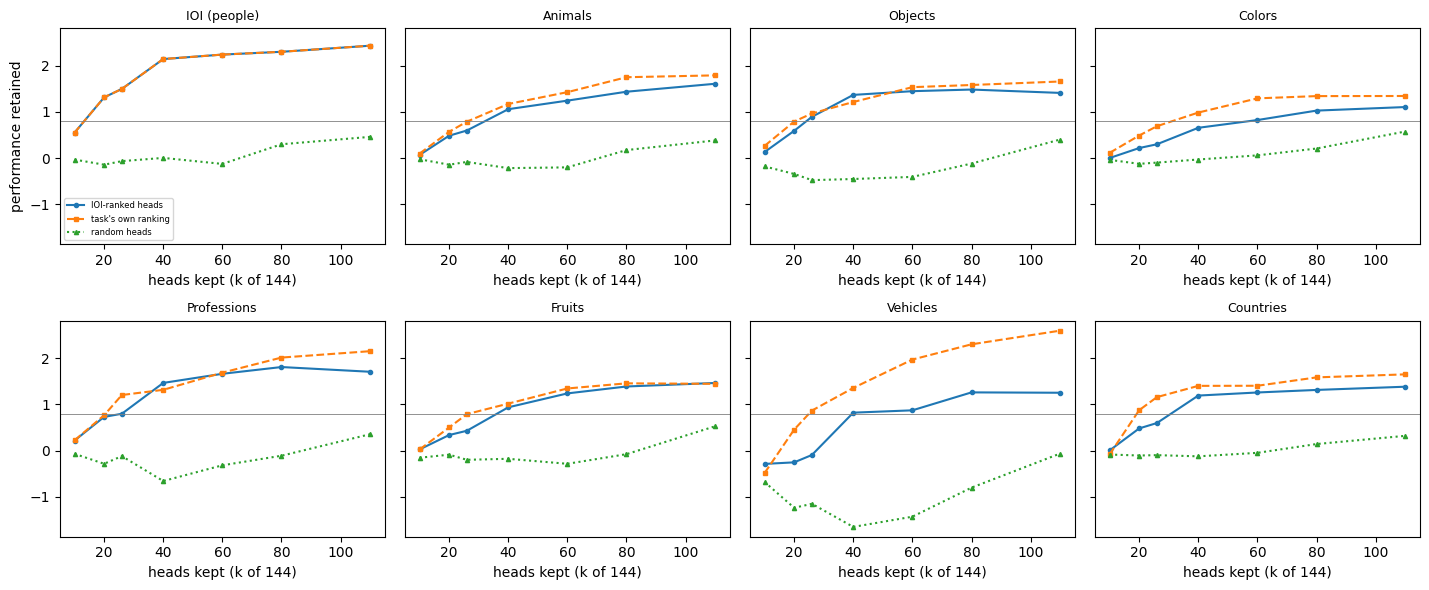

,k for 80% (own ranking),k for 80% (IOI ranking),k for 80% (random)
IOI (people),20,20,>110
Animals,40,40,>110
Objects,26,26,>110
Colors,40,60,>110
Professions,26,40,>110
Fruits,40,40,>110
Vehicles,26,40,>110
Countries,20,40,>110


In [ ]:
KS = [10, 20, 26, 40, 60, 80, 110]
def ranked(mat):
    return [hd for hd, _ in top_heads(mat, n_layers * n_heads, largest=True)]

ioi_rank = ranked(RES["IOI (people)"]["noise"])
rng_p = random.Random(5)
CURVES = {}
for name, td in tqdm(TD.items(), desc="pruning curves"):
    fm, own_rank, rows = td.ld_clean, ranked(RES[name]["noise"]), []
    for k in KS:
        rows.append((k, F(td, ioi_rank[:k]) / fm, F(td, own_rank[:k]) / fm,
                     np.mean([F(td, rng_p.sample(ALL_HEADS, k)) for _ in range(5)]) / fm))
    CURVES[name] = pd.DataFrame(rows, columns=["k", "IOI-ranked heads", "task's own ranking", "random heads"])

ncols = 4; nrows = -(-len(TD) // ncols)
fig, axs = plt.subplots(nrows, ncols, figsize=(3.6 * ncols, 3 * nrows), sharey=True)
for ax, (name, df) in zip(axs.ravel(), CURVES.items()):
    for col, st in zip(df.columns[1:], ["-o", "--s", ":^"]):
        ax.plot(df.k, df[col], st, ms=3, label=col)
    ax.axhline(0.8, color="gray", lw=0.6); ax.set_title(name, fontsize=9); ax.set_xlabel("heads kept (k of 144)")
for ax in axs.ravel()[len(TD):]: ax.axis("off")
axs.ravel()[0].set_ylabel("performance retained"); axs.ravel()[0].legend(fontsize=6)
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/pruning_curves.png", dpi=200); plt.show()

def k_at(df, col, thr=0.8):
    ok = df[df[col] >= thr]
    return int(ok.k.min()) if len(ok) else f">{int(df.k.max())}"
prune_tbl = pd.DataFrame({name: {"k for 80% (own ranking)": k_at(df, "task's own ranking"),
                                 "k for 80% (IOI ranking)": k_at(df, "IOI-ranked heads"),
                                 "k for 80% (random)": k_at(df, "random heads")} for name, df in CURVES.items()}).T
display(prune_tbl)
prune_tbl.to_csv(f"{OUT_DIR}/pruning_k80.csv")
pd.concat(CURVES, names=["task"]).round(4).to_csv(f"{OUT_DIR}/pruning_curves.csv")

In [ ]:
# ---------------- save all numbers ----------------
for name, r in RES.items():
    for key in ("noise", "denoise", "path_logits", "path_B", "path_C"):
        if key in r:
            pd.DataFrame(r[key], index=[f"L{l}" for l in range(n_layers)],
                         columns=[f"H{h}" for h in range(n_heads)]).round(4)\
              .to_csv(f"{OUT_DIR}/{name.split()[0].lower()}_{key}.csv")
print("Saved to ./%s :" % OUT_DIR, sorted(os.listdir(OUT_DIR)))

# Colab only: bundle and download everything
try:
    import shutil
    from google.colab import files
    shutil.make_archive("results", "zip", OUT_DIR)
    files.download("results.zip")
except ImportError:
    pass

Saved to .//content/drive/MyDrive/ioi_project/results : ['animals_noise.csv', 'animals_path_B.csv', 'animals_path_logits.csv', 'colors_noise.csv', 'colors_path_B.csv', 'colors_path_logits.csv', 'completeness.png', 'countries_noise.csv', 'countries_path_B.csv', 'countries_path_logits.csv', 'faithfulness_and_transfer.csv', 'fruits_noise.csv', 'fruits_path_B.csv', 'fruits_path_logits.csv', 'gen_animals_noise.png', 'gen_animals_path_B.png', 'gen_animals_path_logits.png', 'gen_colors_noise.png', 'gen_colors_path_B.png', 'gen_colors_path_logits.png', 'gen_countries_noise.png', 'gen_countries_path_B.png', 'gen_countries_path_logits.png', 'gen_fruits_noise.png', 'gen_fruits_path_B.png', 'gen_fruits_path_logits.png', 'gen_objects_noise.png', 'gen_objects_path_B.png', 'gen_objects_path_logits.png', 'gen_professions_noise.png', 'gen_professions_path_B.png', 'gen_professions_path_logits.png', 'gen_vehicles_noise.png', 'gen_vehicles_path_B.png', 'gen_vehicles_path_logits.png', 'generalization_summa

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>